# Controlled two-task paradigm: A → B → A

**Question.** When a one-module network learns task B after task A, how does A's
geometry change? How much of the change is set by the task relation (Hamming(A, B),
input change s_f) and how much by the learner (richness γ₀)? What does relearning A
recover?

**Slot.** `docs/26` Part B, two-task paradigm: the controlled experiment that comes
before the stream (Kati, 2026-11-06). It is part of the `docs/24` §4 core.

**Pre-commit.** `docs/28` (signed 2026-11-09). Its readings are computed in section 8 and are
the only confirmatory part. Everything else here is observation.

**Self-contained.** Everything lives in `aba_lib.py` next to this notebook: the
generator, the 1M network, training, NTK, and a vendored copy of GLUE. Section 3
asserts that the GLUE copy matches `src.glue.core`.

## 1. Config

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[_v] = "1"          # before numpy is imported anywhere in this kernel

# Mode comes from the environment so the committed notebook runs unchanged in both places:
#   laptop:  QUICK (M=50, n_t=50, n=3);   cluster job: ABA_MODE=full (M=150, n_t=200, n=8).
QUICK = os.environ.get("ABA_MODE", "quick") == "quick"
RUN_GRID = os.environ.get("ABA_RUN_GRID", "1") == "1"      # 0: read the checkpoint only
WORKERS = int(os.environ.get("ABA_WORKERS", "6"))          # spawned workers; 6 is the laptop cap
SEED_OFFSET = int(os.environ.get("ABA_SEED_OFFSET", "0"))  # 8: held-out replication on seeds 8–15 (docs/28 amendment)

import sys, time, json, math, dataclasses
from pathlib import Path
here = Path.cwd().resolve()
REPO = next(p for p in [here, *here.parents] if (p / ".git").exists())
sys.path[:0] = [str(REPO / "notebooks" / "core"), str(REPO)]

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import aba_lib as L

cfg = dataclasses.replace(L.ABAConfig.make(QUICK), seed_offset=SEED_OFFSET)
S0 = cfg.seeds[0]   # first seed of the run: manifolds shown, floor, fresh-noise arms
STAMP = L.git_stamp()

def md_table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))

md_table(["parameter", "value"], [[k, v] for k, v in vars(cfg).items()])
print(f"aba_lib hash {L.lib_hash()}   commit {STAMP['commit']}   dirty {STAMP['dirty']}")
print(f"numpy {np.__version__}   python {sys.version.split()[0]}   cache {L.cache_path(cfg).relative_to(REPO)}")

| parameter | value |
|---|---|
| quick | False |
| P | 16 |
| d | 150 |
| D | 4 |
| R | 1.0 |
| M | 150 |
| N | 300 |
| lr0 | 5.0 |
| n_base | 64 |
| target_loss | 0.05 |
| max_steps | 20000 |
| record_every | 25 |
| n_t | 200 |
| center_policy | all |
| ntk_per_manifold | 20 |
| probe_hamming | 4 |
| n_probe_neutral | 4 |
| refit_steps | 2000 |
| bottleneck_n | 16 |
| gammas | (0.1, 1.0, 10.0) |
| hammings | (0, 4, 8) |
| s_fs | (1.0, 0.9, 0.1) |
| n_seeds | 8 |
| seed_offset | 8 |

aba_lib hash 4e110835b8fc2863   commit 8407a7d3e2be   dirty False
numpy 2.4.6   python 3.11.16   cache results/aba/FULL_4e110835b8fc2863.jsonl


In [2]:
# Palette: reference categorical order (blue, orange, aqua); diverging blue ↔ orange through a neutral grey.
BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3df"
GAMMA_COL = dict(zip(cfg.gammas, [BLUE, AQUA, ORANGE]))   # γ0 = 0.1, 1, 10; validated (dataviz), legends + tables carry identity
LABEL_COL = {1: BLUE, -1: ORANGE}
from matplotlib.colors import LinearSegmentedColormap
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", ORANGE])
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "lines.linewidth": 2.0, "font.size": 9})
CHECKS = []   # (check, PASS/FAIL, detail): validation checks, kept apart from observations
def check(name, ok, detail=""):
    CHECKS.append((name, "PASS" if ok else "**FAIL**", detail))
    print(("PASS " if ok else "FAIL ") + name + (f"  ({detail})" if detail else ""))

## 2. Manifolds

Seed 0 is shown. A and y_A are shared by every cell and both γ₀. B is A's
arrangement with centres redrawn at ρ = s_f (axes and shapes held), labelled by a
dichotomy at the stated Hamming distance from y_A. **At s_f = 1.0, B's points are
A's points exactly.**

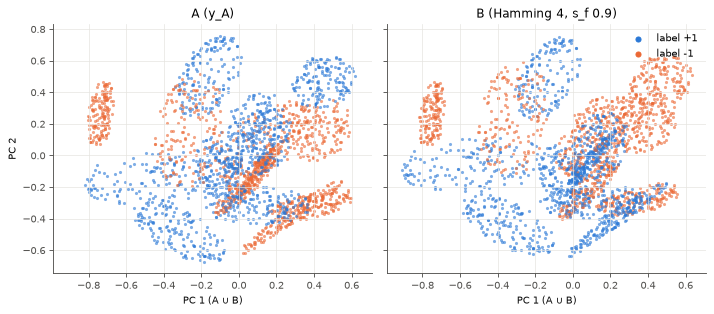

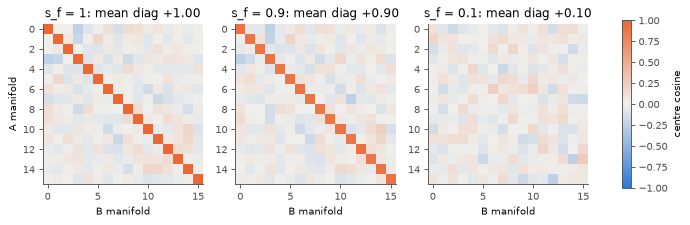

In [3]:
base = L.seed_base(cfg, S0)
H_SHOW, SF_SHOW = 4, 0.9
B_show = L.b_arrangement(cfg, base, SF_SHOW)
pts = np.concatenate([base.A.points.reshape(-1, cfg.d), B_show.points.reshape(-1, cfg.d)])
mu = pts.mean(0); _, _, Vt = np.linalg.svd(pts - mu, full_matrices=False); basis = Vt[:2]

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, arr, y, title in [(axes[0], base.A, base.y_A, "A (y_A)"),
                          (axes[1], B_show, base.y_Bs[H_SHOW], f"B (Hamming {H_SHOW}, s_f {SF_SHOW})")]:
    for m in range(cfg.P):
        Z = (arr.points[m] - mu) @ basis.T
        ax.scatter(Z[:, 0], Z[:, 1], s=8, color=LABEL_COL[int(y[m])], alpha=0.6, linewidths=0)
    ax.set_title(title); ax.set_xlabel("PC 1 (A ∪ B)")
axes[0].set_ylabel("PC 2")
for lab, col in LABEL_COL.items():
    axes[1].scatter([], [], color=col, s=20, label=f"label {lab:+d}")
axes[1].legend(frameon=False, loc="upper right"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(cfg.s_fs), figsize=(11, 3.4))
for ax, sf in zip(axes, cfg.s_fs):
    C = L.centre_cosines(base.A.centers, L.b_arrangement(cfg, base, sf).centers)
    im = ax.imshow(C, cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_title(f"s_f = {sf:g}: mean diag {np.mean(np.diag(C)):+.2f}"); ax.set_xlabel("B manifold"); ax.grid(False)
axes[0].set_ylabel("A manifold"); fig.colorbar(im, ax=axes, shrink=0.8, label="centre cosine"); plt.show()

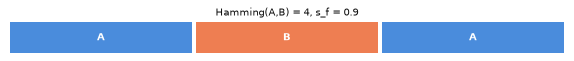

label relations, seed 8 (signed s_r = 1 − 2·Hamming/P):


| Hamming(A,B) | s_r(y_A, y_B) | s_r(y*, y_A) | s_r(y*, y_B) |
|---|---|---|---|
| 0 | +1.000 | +0.500 | +0.500 |
| 4 | +0.500 | +0.500 | +0.250 |
| 8 | +0.000 | +0.500 | -0.500 |

In [4]:
def stream_strip(ax, h, sf, widths=(1, 1, 1)):
    x = 0
    for (lab, col), w in zip([("A", BLUE), ("B", ORANGE), ("A", BLUE)], widths):
        ax.add_patch(plt.Rectangle((x + 0.01, 0), w - 0.02, 1, color=col, alpha=0.85, linewidth=0))
        ax.text(x + w / 2, 0.5, lab, ha="center", va="center", color="white", fontsize=9, weight="bold")
        x += w
    ax.set_xlim(0, x); ax.set_ylim(0, 1); ax.axis("off")
    ax.set_title(f"Hamming(A,B) = {h}, s_f = {sf:g}", fontsize=9, color=INK)

fig, ax = plt.subplots(figsize=(9, 0.5)); stream_strip(ax, H_SHOW, SF_SHOW); plt.show()
print(f"label relations, seed {S0} (signed s_r = 1 − 2·Hamming/P):")
md_table(["Hamming(A,B)", "s_r(y_A, y_B)", "s_r(y*, y_A)", "s_r(y*, y_B)"],
         [[h, f"{L.s_r(base.y_A, yb):+.3f}", f"{L.s_r(base.y_star, base.y_A):+.3f}",
           f"{L.s_r(base.y_star, yb):+.3f}"] for h, yb in base.y_Bs.items()])

## 3. Estimator validation (must pass)

In [5]:
# (a) Vendored GLUE equals src.glue.core on one example, when src imports.
try:
    from src.glue.core import glue_measures as src_glue, Ensemble as SrcEnsemble
except Exception as e:  # noqa: BLE001
    src_glue = None; print("src not importable, comparison skipped:", e)
if src_glue is not None:
    mans = L.as_manifolds(base.A.points)
    y = base.y_A.astype(float)
    a = L.glue_measures(mans, np.random.default_rng(11), n_t=20, ensemble=L.Ensemble("retained", y)).to_dict()
    b = src_glue(mans, np.random.default_rng(11), n_t=20, ensemble=SrcEnsemble("retained", y)).to_dict()
    diff = max(abs(a[k] - b[k]) for k in a if isinstance(a[k], float))
    assert diff == 0.0, f"vendored GLUE differs from src.glue.core by {diff}"
    check("vendored GLUE == src.glue.core (retained y_A, input manifolds)", True, f"max |diff| = {diff:g}")

PASS vendored GLUE == src.glue.core (retained y_A, input manifolds)  (max |diff| = 0)


In [6]:
# (b) Identity residual and (c) capacity falls with R and with D, on input manifolds.
rows, alphas_R, alphas_D, resid = [], [], [], []
for R in (0.5, 1.0, 2.0):
    arr = L.make_arrangement(cfg.P, cfg.d, cfg.D, R, cfg.M, np.random.default_rng([7, 1]), np.random.default_rng([7, 2]))
    g = L.capacity(L.as_manifolds(arr.points), base.y_A, cfg, [L.SALT, 0, 9])
    alphas_R.append(g["alpha"]); resid.append(g["identity_residual"]); rows.append([f"R={R}, D={cfg.D}", f"{g['alpha']:.4f}", f"{g['identity_residual']:.1e}"])
for D in (2, 4, 8):
    arr = L.make_arrangement(cfg.P, cfg.d, D, cfg.R, cfg.M, np.random.default_rng([7, 1]), np.random.default_rng([7, 2]))
    g = L.capacity(L.as_manifolds(arr.points), base.y_A, cfg, [L.SALT, 0, 9])
    alphas_D.append(g["alpha"]); resid.append(g["identity_residual"]); rows.append([f"R={cfg.R}, D={D}", f"{g['alpha']:.4f}", f"{g['identity_residual']:.1e}"])
md_table(["input manifolds", "α (retained y_A)", "identity residual"], rows)
check("identity residual ≈ 0", max(resid) < 1e-10, f"max {max(resid):.1e}")
check("capacity falls as R grows (0.5 → 1 → 2)", bool(np.all(np.diff(alphas_R) < 0)), str([round(a, 4) for a in alphas_R]))
check("capacity falls as D grows (2 → 4 → 8)", bool(np.all(np.diff(alphas_D) < 0)), str([round(a, 4) for a in alphas_D]))

| input manifolds | α (retained y_A) | identity residual |
|---|---|---|
| R=0.5, D=4 | 0.6520 | 0.0e+00 |
| R=1.0, D=4 | 0.4014 | 0.0e+00 |
| R=2.0, D=4 | 0.2896 | 0.0e+00 |
| R=1.0, D=2 | 0.6362 | 0.0e+00 |
| R=1.0, D=4 | 0.4014 | 0.0e+00 |
| R=1.0, D=8 | 0.2725 | 0.0e+00 |

PASS identity residual ≈ 0  (max 0.0e+00)
PASS capacity falls as R grows (0.5 → 1 → 2)  ([0.652, 0.4014, 0.2896])
PASS capacity falls as D grows (2 → 4 → 8)  ([0.6362, 0.4014, 0.2725])


In [7]:
# (d) Noise floor: SD of log α over K estimator seeds, on the init representation (identical across γ0).
K_FLOOR = 6 if QUICK else 8
net0 = L.OneModuleNet(base.W0, 1.0, cfg)
P_, M_, d_ = base.A.points.shape
Hrep = net0.hidden(base.A.points.reshape(-1, d_)).reshape(P_, M_, -1)
logs = [math.log(L.capacity(L.as_manifolds(Hrep), base.y_A, cfg, [L.SALT, 0, 1000 + k])["alpha"]) for k in range(K_FLOOR)]
FLOOR_INIT = float(np.std(logs, ddof=1))
print(f"INIT floor (reference only; hidden representation at initialisation, identical across γ0): "
      f"SD(log α) over {K_FLOOR} estimator seeds = {FLOOR_INIT:.4f}  (n_t = {cfg.n_t})")
print("Effects are resolved against the per-γ0 floors on the TRAINED representation (section 4).")

INIT floor (reference only; hidden representation at initialisation, identical across γ0): SD(log α) over 8 estimator seeds = 0.0143  (n_t = 200)
Effects are resolved against the per-γ0 floors on the TRAINED representation (section 4).


## 4. Network validation (must pass)

In [8]:
nets = {g: L.OneModuleNet(base.W0, g, cfg) for g in cfg.gammas}
XA, yA = L.flatten(base.A.points, base.y_A)
check("initial loss = 0.5 for every γ0", all(n.loss(XA, yA) == 0.5 for n in nets.values()),
      str({g: n.loss(XA, yA) for g, n in nets.items()}))
check("hidden init identical across γ0 (bitwise)", all(np.array_equal(nets[cfg.gammas[0]].W, nets[g].W) for g in cfg.gammas))
probe = np.concatenate([base.A.points[m, base.ntk_idx[m]] for m in range(cfg.P)])
_, KW0 = nets[cfg.gammas[0]].ntk_blocks(probe)
check("K_W(0) = 0 (readout starts at 0)", float(np.abs(KW0).max()) == 0.0)
tmp = L.OneModuleNet(base.W0, 1.0, cfg); tmp.u = np.random.default_rng(3).standard_normal(cfg.N)
fd = L.ntk_fd_check(tmp, probe[:3], np.random.default_rng(4))
check("analytic NTK: J Jᵀ = K_u + K_W and J δ = finite difference",
      fd["K_vs_JJt_rel"] < 1e-12 and fd["Jdelta_vs_fd_rel"] < 1e-5, str({k: f"{v:.1e}" for k, v in fd.items()}))

PASS initial loss = 0.5 for every γ0  ({0.1: 0.5, 1.0: 0.5, 10.0: 0.5})
PASS hidden init identical across γ0 (bitwise)
PASS K_W(0) = 0 (readout starts at 0)
PASS analytic NTK: J Jᵀ = K_u + K_W and J δ = finite difference  ({'K_vs_JJt_rel': '2.8e-16', 'Jdelta_vs_fd_rel': '2.5e-07'})


In [9]:
# Lazy/rich separation after A, and reaching the target within budget, for every seed and γ0.
sep_rows, sep, budget_ok = [], {}, []
for seed in cfg.seeds:
    b = L.seed_base(cfg, seed)
    X, y = L.flatten(b.A.points, b.y_A)
    pr = np.concatenate([b.A.points[m, b.ntk_idx[m]] for m in range(cfg.P)])
    yp = np.repeat(b.y_A.astype(float), b.ntk_idx.shape[1])
    for g in cfg.gammas:
        n = L.OneModuleNet(b.W0, g, cfg); Ku0, KW0 = n.ntk_blocks(pr)
        t = L.train_to_criterion(n, X, y, cfg)
        budget_ok.append((seed, g, t["status"], t["steps"]))
        sep[(seed, g)] = L.richness_snapshot(n, Ku0 + KW0, Ku0, pr, yp, pr, yp)[0]
display(Markdown("**NTK change after training on A: absolute values, not ratios.** All three are "
                  "‖·‖_F / ‖K(0)‖_F on A's fixed probe set; K(0) = K_u(0) because K_W(0) = 0. "
                  "ΔK_W is the hidden-weight block grown from zero; ΔK full = ‖ΔK_u + K_W‖."))
NTK_KEYS = [("dK_full", "ΔK full"), ("dK_u", "ΔK_u"), ("dK_W", "ΔK_W"), ("weight_change", "weight change")]
rows = []
for g in cfg.gammas:
    for seed in cfg.seeds:
        rows.append([f"{g:g}", seed] + [f"{sep[(seed, g)][k]:.4g}" for k, _ in NTK_KEYS])
    rows.append([f"**{g:g}**", "**mean**"] + [f"**{np.mean([sep[(s, g)][k] for s in cfg.seeds]):.4g}**" for k, _ in NTK_KEYS])
md_table(["γ0", "seed"] + [lab for _, lab in NTK_KEYS], rows)
for k in ("weight_change", "dK_u", "dK_full"):
    check(f"increases with γ0 after A in {k}, every seed",
          all(sep[(s, hi)][k] > sep[(s, lo)][k] for s in cfg.seeds for lo, hi in zip(cfg.gammas, cfg.gammas[1:])),
          "direction only; any ratio threshold is Kati's")
md_table(["seed", "γ0", "status", "steps on A"], [[s, f"{g:g}", st, n] for s, g, st, n in budget_ok])
check(f"every γ0 reaches loss {cfg.target_loss} within {cfg.max_steps} steps at lr0 = {cfg.lr0}",
      all(st == "converged" for _, _, st, _ in budget_ok), "a failure is reported, never re-pinned")

**NTK change after training on A: absolute values, not ratios.** All three are ‖·‖_F / ‖K(0)‖_F on A's fixed probe set; K(0) = K_u(0) because K_W(0) = 0. ΔK_W is the hidden-weight block grown from zero; ΔK full = ‖ΔK_u + K_W‖.

| γ0 | seed | ΔK full | ΔK_u | ΔK_W | weight change |
|---|---|---|---|---|---|
| 0.1 | 8 | 0.2245 | 0.04881 | 0.2003 | 0.02233 |
| 0.1 | 9 | 0.208 | 0.04764 | 0.184 | 0.02217 |
| 0.1 | 10 | 0.1999 | 0.05185 | 0.1724 | 0.02095 |
| 0.1 | 11 | 0.2249 | 0.04717 | 0.2019 | 0.02567 |
| 0.1 | 12 | 0.2028 | 0.04738 | 0.1792 | 0.02061 |
| 0.1 | 13 | 0.2259 | 0.04752 | 0.2029 | 0.02699 |
| 0.1 | 14 | 0.1931 | 0.04472 | 0.1708 | 0.02126 |
| 0.1 | 15 | 0.1949 | 0.04783 | 0.1704 | 0.021 |
| **0.1** | **mean** | **0.2092** | **0.04786** | **0.1852** | **0.02262** |
| 1 | 8 | 3.33 | 0.7 | 2.976 | 0.1629 |
| 1 | 9 | 3.095 | 0.6854 | 2.747 | 0.161 |
| 1 | 10 | 3.125 | 0.8043 | 2.688 | 0.1536 |
| 1 | 11 | 3.135 | 0.6362 | 2.821 | 0.1685 |
| 1 | 12 | 3.104 | 0.7273 | 2.733 | 0.1583 |
| 1 | 13 | 3.047 | 0.6156 | 2.745 | 0.1699 |
| 1 | 14 | 2.93 | 0.6546 | 2.602 | 0.1581 |
| 1 | 15 | 2.89 | 0.6949 | 2.531 | 0.1547 |
| **1** | **mean** | **3.082** | **0.6898** | **2.73** | **0.1609** |
| 10 | 8 | 38.66 | 8.035 | 34.8 | 0.6513 |
| 10 | 9 | 35.1 | 7.669 | 31.41 | 0.6374 |
| 10 | 10 | 35.52 | 9.115 | 30.75 | 0.6167 |
| 10 | 11 | 35.21 | 6.973 | 31.93 | 0.6524 |
| 10 | 12 | 35.36 | 8.201 | 31.34 | 0.6365 |
| 10 | 13 | 33.65 | 6.747 | 30.49 | 0.6568 |
| 10 | 14 | 33.37 | 7.524 | 29.75 | 0.6333 |
| 10 | 15 | 32.98 | 7.918 | 29.05 | 0.6203 |
| **10** | **mean** | **34.98** | **7.773** | **31.19** | **0.6381** |

PASS increases with γ0 after A in weight_change, every seed  (direction only; any ratio threshold is Kati's)
PASS increases with γ0 after A in dK_u, every seed  (direction only; any ratio threshold is Kati's)
PASS increases with γ0 after A in dK_full, every seed  (direction only; any ratio threshold is Kati's)


| seed | γ0 | status | steps on A |
|---|---|---|---|
| 8 | 0.1 | converged | 1905 |
| 8 | 1 | converged | 350 |
| 8 | 10 | converged | 52 |
| 9 | 0.1 | converged | 1972 |
| 9 | 1 | converged | 351 |
| 9 | 10 | converged | 51 |
| 10 | 0.1 | converged | 2011 |
| 10 | 1 | converged | 331 |
| 10 | 10 | converged | 47 |
| 11 | 0.1 | converged | 2226 |
| 11 | 1 | converged | 378 |
| 11 | 10 | converged | 54 |
| 12 | 0.1 | converged | 1871 |
| 12 | 1 | converged | 350 |
| 12 | 10 | converged | 51 |
| 13 | 0.1 | converged | 2266 |
| 13 | 1 | converged | 373 |
| 13 | 10 | converged | 54 |
| 14 | 0.1 | converged | 1761 |
| 14 | 1 | converged | 330 |
| 14 | 10 | converged | 49 |
| 15 | 0.1 | converged | 1833 |
| 15 | 1 | converged | 327 |
| 15 | 10 | converged | 48 |

PASS every γ0 reaches loss 0.05 within 20000 steps at lr0 = 5.0  (a failure is reported, never re-pinned)


In [10]:
# Noise floor per γ0 on the hidden representation AFTER training on A (first seed of the run, S0; K estimator seeds).
FLOORS = {g: L.trained_floor(cfg, g, seed=S0, K=K_FLOOR) for g in cfg.gammas}
md_table(["γ0", "floor SD(log α_A), trained", "K", "n_t", "mean log α_A after A"],
         [[f"{g:g}", f"{f['floor']:.4f}", f["K"], f["n_t"], f"{f['mean_log_alpha']:+.3f}"] for g, f in FLOORS.items()]
         + [["init (reference)", f"{FLOOR_INIT:.4f}", K_FLOOR, cfg.n_t, ""]])
T975 = {2: 4.303, 3: 3.182, 4: 2.776, 5: 2.571, 6: 2.447, 7: 2.365, 8: 2.306}   # t quantiles, df = n − 1 ≥ 2

def resolve(values, floor):
    # docs/26 A4: resolved iff the 95% t-interval over unique draws excludes 0 AND |mean| ≥ 2 floors.
    v = np.asarray(values, float); n = v.size; m = float(v.mean())
    if n < 2: return {"mean": m, "lo": float("nan"), "hi": float("nan"), "n": n, "resolved": False, "sign": 0}
    h = T975.get(n - 1, 1.96) * float(v.std(ddof=1)) / math.sqrt(n)
    res = (m - h > 0 or m + h < 0) and abs(m) >= 2 * floor
    return {"mean": m, "lo": m - h, "hi": m + h, "n": n, "resolved": bool(res), "sign": int(np.sign(m)) if res else 0}

| γ0 | floor SD(log α_A), trained | K | n_t | mean log α_A after A |
|---|---|---|---|---|
| 0.1 | 0.0248 | 8 | 200 | -0.971 |
| 1 | 0.0354 | 8 | 200 | -0.088 |
| 10 | 0.0428 | 8 | 200 | +0.893 |
| init (reference) | 0.0143 | 8 | 200 |  |

## Expectations (written before the grid)

These are directions from earlier signal, not thresholds. They were written on
2026-11-08 before any grid arm ran. After the run, each reading quotes them verbatim
and marks it **held**, **not held**, or **unresolved at floor**.

1. forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1;
2. at γ0 = 10, the utility channel carries most of Δlog α_A;
3. Hamming 0 under drift (s_f 0.9) gives Δlog α_A > 0 (gain);
4. Hamming 4 and 8 are similar (cliff, not dose);
5. K_u change separates γ0 more cleanly than the full NTK change.

**How each is read.** This is fixed before the run.

**Measure.** Δlog α_A means A's retained capacity from the end of A to the end
of B (`backward.A1_to_B`).

**Resolution rule.** "Resolved" means the 95% t-interval over the n unique draws
excludes 0 **and** |mean| ≥ 2 floors. The floor is the per-γ0 trained-representation
floor. For contrasts across γ0, the floor is the larger of the two.

**Rules per expectation:**

| # | statistic | held | not held | unresolved |
|---|---|---|---|---|
| 1 | per s_f, paired per seed: d = Δlog α_A(γ0=10) − Δlog α_A(γ0=0.1) at Hamming 8 | d resolved < 0 | d resolved > 0 | otherwise |
| 2 | at γ0 = 10, per cell with Hamming ∈ {4, 8} and per (Hamming 0, s_f ∈ {0.9, 0.1}): utility fraction = mean utility / mean total | total resolved and fraction > 0.5 | total resolved and fraction ≤ 0.5 | total unresolved |
| 3 | per γ0: Δlog α_A at Hamming 0, s_f 0.9 | resolved > 0 | resolved < 0 | otherwise |
| 4 | per (γ0, s_f), paired per seed: d = Δlog α_A(Hamming 8) − Δlog α_A(Hamming 4) | 95% interval of d inside ±2 floors (equivalence) | d resolved (differs) | otherwise |
| 5 | after A, over unique (seed, γ0): separation d′ = (mean log x at γ0=10 − mean log x at γ0=0.1) / pooled SD of log x, for x = ΔK_u and x = ΔK full | d′(ΔK_u) > d′(ΔK full) | d′(ΔK_u) ≤ d′(ΔK full) | not used (no capacity floor applies) |

Expectation 5 also reports the absolute lazy values, which are expected to be ≪ 1.

Stratified readings are not pooled. An expectation that holds in some strata and not
others is reported stratum by stratum.

## 5. Runs

**Timing first.** One QUICK arm runs in a spawned worker before anything else. The arm
is γ₀ = 0.1, Hamming 8, s_f = 0.1: lazy training takes the most steps, so this is
expected to be the slowest cell. The full grid runs only when `RUN_GRID = True`. It
includes the identity control (Hamming 0, s_f 1.0) and a **fresh-noise identity
arm**: same manifolds, ε noise redrawn, seed 0, every γ₀. That arm checks the
"frozen = exact copy" choice. Every arm is checkpointed to `results/aba/`, keyed by
the `aba_lib` hash and the config.

In [11]:
TIMING_SPEC = L.ArmSpec(0, cfg.gammas[0], max(cfg.hammings), min(cfg.s_fs))
t0 = time.perf_counter()
timing_arm = L.run_grid(cfg, [TIMING_SPEC], workers=1)[0]
tm = timing_arm["timing"]
print(f"timing arm {TIMING_SPEC.key}: wall {tm['wall_s']:.1f}s in worker "
      f"(train {tm['train_s']:.1f}s, GLUE {tm['glue_s']:.1f}s, NTK {tm['ntk_s']:.1f}s); "
      f"cell {time.perf_counter() - t0:.1f}s incl. spawn or cache load")
print("steps:", timing_arm["behaviour"]["steps"], " usable:", timing_arm["usable"])

[1/1] seed=0,gamma=0.1,H=8,s_f=0.1  wall 147s  usable=True
timing arm seed=0,gamma=0.1,H=8,s_f=0.1: wall 146.5s in worker (train 83.4s, GLUE 61.1s, NTK 0.0s); cell 147.8s incl. spawn or cache load
steps: {'A1': 1630, 'B': 1509, 'A2': 369, 'freshB': 1751}  usable: True


In [12]:
if RUN_GRID:
    t0 = time.perf_counter()
    L.run_grid(cfg, L.all_specs(cfg), workers=WORKERS)
    GRID_WALL = time.perf_counter() - t0
    print(f"grid: {len(L.all_specs(cfg))} arms requested, wall {GRID_WALL:.0f}s on {WORKERS} workers")
WANT = {s.key for s in L.all_specs(cfg)}   # this run's seeds only; other rows in the checkpoint are ignored
loaded = [r for r in L.load_results(cfg) if r["key"] in WANT]
check(f"every requested arm is in the checkpoint (seeds {cfg.seeds.start}–{cfg.seeds.stop - 1})", len(loaded) == len(WANT),
      f"{len(loaded)} of {len(WANT)}")
FRESH = [r for r in loaded if r["spec"].get("noise", "copy") == "fresh"]
arms = [r for r in loaded if r["usable"] and r["spec"].get("noise", "copy") == "copy"]
unusable = [r["key"] for r in loaded if not r["usable"]]
print(f"{len(arms)} usable design arms + {len(FRESH)} fresh-noise arms loaded; unusable: {unusable or 'none'}")
stamps = {(r["stamp"]["commit"], r["stamp"]["dirty"], r["lib_hash"]) for r in loaded}
print("provenance (commit, dirty, lib hash):", stamps)
check("every arm stamped with a clean tree", all(r["stamp"]["dirty"] is False for r in loaded),
      str(sorted({str(s[1]) for s in stamps})))

PASS every requested arm is in the checkpoint (seeds 8–15)  (219 of 219)
216 usable design arms + 3 fresh-noise arms loaded; unusable: none
provenance (commit, dirty, lib hash): {('8407a7d3e2be', False, '4e110835b8fc2863')}
PASS every arm stamped with a clean tree  (['False'])


In [13]:
# Identity control (exact copy) and the fresh-noise identity arm, both read from the grid.
for r in [x for x in arms if x["spec"]["hamming"] == 0 and x["spec"]["s_f"] == 1.0 and x["spec"]["seed"] == S0]:
    st, bw = r["behaviour"]["steps"], r["backward"]
    ok = (st["B"] == 0 and st["A2"] == 0 and r["behaviour"]["forget_B_loss"]["forgetting"] == 0.0
          and all(v == 0.0 for v in bw["A1_to_B"].values()) and all(v == 0.0 for v in bw["A1_to_A2"].values()))
    check(f"identity control (Hamming 0, s_f 1.0, copy), γ0={r['spec']['gamma']:g}: 0 steps on B and A2, zero forgetting, Δlog α_A = 0",
          ok, f"steps {st}")
rows = []
for r in sorted(FRESH, key=lambda x: x["spec"]["gamma"]):
    g = r["spec"]["gamma"]; st = r["behaviour"]["steps"]; d = r["backward"]["A1_to_B"]["total"]
    fl = r["behaviour"]["forget_B_loss"]["forgetting"]
    rows.append([f"{g:g}", st["A1"], st["B"], st["A2"], f"{d:+.5f}", f"{d / FLOORS[g]['floor']:+.3f}",
                 f"{fl:+.2e}", f"{r['behaviour']['first_loss']['B']:.5f}"])
    check(f"fresh-noise identity, γ0={g:g}: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target",
          abs(d) < FLOORS[g]["floor"] and r["behaviour"]["first_loss"]["B"] < 2 * cfg.target_loss,
          f"Δlog α_A = {d:+.5f} ({d / FLOORS[g]['floor']:+.2f} floors), steps on B = {st['B']}")
md_table(["γ0", "steps A1", "steps B", "steps A2", "Δlog α_A (A1→B)", "in floors", "forgetting (test loss)", "zero-shot loss on B"], rows)

PASS identity control (Hamming 0, s_f 1.0, copy), γ0=10: 0 steps on B and A2, zero forgetting, Δlog α_A = 0  (steps {'A1': 52, 'B': 0, 'A2': 0, 'freshB': 52})
PASS identity control (Hamming 0, s_f 1.0, copy), γ0=1: 0 steps on B and A2, zero forgetting, Δlog α_A = 0  (steps {'A1': 350, 'B': 0, 'A2': 0, 'freshB': 350})
PASS identity control (Hamming 0, s_f 1.0, copy), γ0=0.1: 0 steps on B and A2, zero forgetting, Δlog α_A = 0  (steps {'A1': 1905, 'B': 0, 'A2': 0, 'freshB': 1905})
PASS fresh-noise identity, γ0=0.1: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target  (Δlog α_A = +0.00000 (+0.00 floors), steps on B = 0)
PASS fresh-noise identity, γ0=1: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target  (Δlog α_A = +0.00000 (+0.00 floors), steps on B = 0)
PASS fresh-noise identity, γ0=10: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target  (Δlog α_A = +0.00000 (+0.00 floors), steps on B = 0)


| γ0 | steps A1 | steps B | steps A2 | Δlog α_A (A1→B) | in floors | forgetting (test loss) | zero-shot loss on B |
|---|---|---|---|---|---|---|---|
| 0.1 | 1905 | 0 | 0 | +0.00000 | +0.000 | +0.00e+00 | 0.04999 |
| 1 | 350 | 0 | 0 | +0.00000 | +0.000 | +0.00e+00 | 0.04947 |
| 10 | 52 | 0 | 0 | +0.00000 | +0.000 | +0.00e+00 | 0.04569 |

### Per-arm output schema

Every arm must carry each field below, finite. Groups:
- **backward:** Δlog α_A in three channels plus total and residual, at each phase
  (init→A, A→B, B→A, A→ABA).
- **forgetting:** against the running max (accuracy) or running min (loss).
- **forward:** FT_geo with the neutral probes y\*_k (s_r = 0 to y_A; specific = Δlog α_{y_B}
  − mean_k Δlog α_{y*_k}), the anchored y\* kept for comparison, and the signed s_r relations.
- **refit:** a fresh readout fitted on frozen features at init, after A, after B and after A
  again (fixed budget `cfg.refit_steps`), scored on A's test points.
- **behaviour:** FT_beh against a fresh learner, savings, raw steps, and zero-shot
  losses.
- **richness:** weight change, r_t, ΔK full, ΔK_u and ΔK_W from init and from the previous
  boundary (`*_step`, plus kernel alignment `align_step`), NTK–label alignment.
- **geometry:** ρ_c signed and `glue`.

In [14]:
md_table(["field", "meaning"], [[f"`{k}`", v] for k, v in L.SCHEMA.items()])
bad = {r["key"]: L.check_schema(r) for r in loaded}
bad = {k: v for k, v in bad.items() if v}
assert not bad, f"schema violations: {bad}"
check(f"schema: all {len(L.SCHEMA)} fields present and finite in all {len(loaded)} arms", True)

| field | meaning |
|---|---|
| `backward.init_to_A1.total` | Δlog α_A init_to_A1, channel total |
| `backward.init_to_A1.utility` | Δlog α_A init_to_A1, channel utility |
| `backward.init_to_A1.radius` | Δlog α_A init_to_A1, channel radius |
| `backward.init_to_A1.dimension` | Δlog α_A init_to_A1, channel dimension |
| `backward.init_to_A1.residual` | Δlog α_A init_to_A1, channel residual |
| `backward.A1_to_B.total` | Δlog α_A A1_to_B, channel total |
| `backward.A1_to_B.utility` | Δlog α_A A1_to_B, channel utility |
| `backward.A1_to_B.radius` | Δlog α_A A1_to_B, channel radius |
| `backward.A1_to_B.dimension` | Δlog α_A A1_to_B, channel dimension |
| `backward.A1_to_B.residual` | Δlog α_A A1_to_B, channel residual |
| `backward.B_to_A2.total` | Δlog α_A B_to_A2, channel total |
| `backward.B_to_A2.utility` | Δlog α_A B_to_A2, channel utility |
| `backward.B_to_A2.radius` | Δlog α_A B_to_A2, channel radius |
| `backward.B_to_A2.dimension` | Δlog α_A B_to_A2, channel dimension |
| `backward.B_to_A2.residual` | Δlog α_A B_to_A2, channel residual |
| `backward.A1_to_A2.total` | Δlog α_A A1_to_A2, channel total |
| `backward.A1_to_A2.utility` | Δlog α_A A1_to_A2, channel utility |
| `backward.A1_to_A2.radius` | Δlog α_A A1_to_A2, channel radius |
| `backward.A1_to_A2.dimension` | Δlog α_A A1_to_A2, channel dimension |
| `backward.A1_to_A2.residual` | Δlog α_A A1_to_A2, channel residual |
| `behaviour.forget_B_acc.peak` | forgetting on A during B vs running max (peak) |
| `behaviour.forget_B_acc.final` | forgetting on A during B vs running max (final) |
| `behaviour.forget_B_acc.forgetting` | forgetting on A during B vs running max (forgetting) |
| `behaviour.forget_B_loss.peak` | forgetting on A during B vs running min (peak) |
| `behaviour.forget_B_loss.final` | forgetting on A during B vs running min (final) |
| `behaviour.forget_B_loss.forgetting` | forgetting on A during B vs running min (forgetting) |
| `forward.total.total` | Δlog α_{y_B} on B's manifolds, init → after A, total |
| `forward.total.utility` | Δlog α_{y_B} on B's manifolds, init → after A, utility |
| `forward.total.radius` | Δlog α_{y_B} on B's manifolds, init → after A, radius |
| `forward.total.dimension` | Δlog α_{y_B} on B's manifolds, init → after A, dimension |
| `forward.total.residual` | Δlog α_{y_B} on B's manifolds, init → after A, residual |
| `forward.ystar_neutral.0` | Δlog α_{y*_0} (neutral, s_r = 0 to y_A) on B's manifolds, init → after A |
| `forward.ystar_neutral.1` | Δlog α_{y*_1} (neutral, s_r = 0 to y_A) on B's manifolds, init → after A |
| `forward.ystar_neutral.2` | Δlog α_{y*_2} (neutral, s_r = 0 to y_A) on B's manifolds, init → after A |
| `forward.ystar_neutral.3` | Δlog α_{y*_3} (neutral, s_r = 0 to y_A) on B's manifolds, init → after A |
| `forward.ystar_neutral.mean` | Δlog α_{y*_mean} (neutral, s_r = 0 to y_A) on B's manifolds, init → after A |
| `forward.specific` | FT_geo specific = Δlog α_{y_B} − mean_k Δlog α_{y*_k} (neutral baseline) |
| `forward.ystar_anchored` | Δlog α_{y*} for the anchored probe (s_r = +0.5 to y_A); comparison only |
| `forward.specific_anchored` | Δlog α_{y_B} − Δlog α_{y* anchored}; comparison only |
| `relations.s_r_AB` | s_r(y_A, y_B), signed |
| `relations.s_r_ystar_A` | s_r(y* anchored, y_A), signed |
| `relations.s_r_ystar_B` | s_r(y* anchored, y_B), signed |
| `relations.s_r_ystar_neutral_A.0` | s_r(y*_0 neutral, y_A) |
| `relations.s_r_ystar_neutral_A.1` | s_r(y*_1 neutral, y_A) |
| `relations.s_r_ystar_neutral_A.2` | s_r(y*_2 neutral, y_A) |
| `relations.s_r_ystar_neutral_A.3` | s_r(y*_3 neutral, y_A) |
| `relations.s_r_ystar_neutral_B.0` | s_r(y*_0 neutral, y_B) |
| `relations.s_r_ystar_neutral_B.1` | s_r(y*_1 neutral, y_B) |
| `relations.s_r_ystar_neutral_B.2` | s_r(y*_2 neutral, y_B) |
| `relations.s_r_ystar_neutral_B.3` | s_r(y*_3 neutral, y_B) |
| `refit.init.loss` | fresh readout on frozen features after init, loss |
| `refit.init.acc` | fresh readout on frozen features after init, acc |
| `refit.init.train_loss` | fresh readout on frozen features after init, train_loss |
| `refit.init.loss@100` | fresh readout on frozen features after init, loss@100 |
| `refit.init.acc@100` | fresh readout on frozen features after init, acc@100 |
| `refit.init.loss@500` | fresh readout on frozen features after init, loss@500 |
| `refit.init.acc@500` | fresh readout on frozen features after init, acc@500 |
| `refit.A1.loss` | fresh readout on frozen features after A1, loss |
| `refit.A1.acc` | fresh readout on frozen features after A1, acc |
| `refit.A1.train_loss` | fresh readout on frozen features after A1, train_loss |
| `refit.A1.loss@100` | fresh readout on frozen features after A1, loss@100 |
| `refit.A1.acc@100` | fresh readout on frozen features after A1, acc@100 |
| `refit.A1.loss@500` | fresh readout on frozen features after A1, loss@500 |
| `refit.A1.acc@500` | fresh readout on frozen features after A1, acc@500 |
| `refit.B.loss` | fresh readout on frozen features after B, loss |
| `refit.B.acc` | fresh readout on frozen features after B, acc |
| `refit.B.train_loss` | fresh readout on frozen features after B, train_loss |
| `refit.B.loss@100` | fresh readout on frozen features after B, loss@100 |
| `refit.B.acc@100` | fresh readout on frozen features after B, acc@100 |
| `refit.B.loss@500` | fresh readout on frozen features after B, loss@500 |
| `refit.B.acc@500` | fresh readout on frozen features after B, acc@500 |
| `refit.A2.loss` | fresh readout on frozen features after A2, loss |
| `refit.A2.acc` | fresh readout on frozen features after A2, acc |
| `refit.A2.train_loss` | fresh readout on frozen features after A2, train_loss |
| `refit.A2.loss@100` | fresh readout on frozen features after A2, loss@100 |
| `refit.A2.acc@100` | fresh readout on frozen features after A2, acc@100 |
| `refit.A2.loss@500` | fresh readout on frozen features after A2, loss@500 |
| `refit.A2.acc@500` | fresh readout on frozen features after A2, acc@500 |
| `bottleneck.init.loss` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after init, loss |
| `bottleneck.init.acc` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after init, acc |
| `bottleneck.init.train_loss` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after init, train_loss |
| `bottleneck.init.loss@100` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after init, loss@100 |
| `bottleneck.init.acc@100` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after init, acc@100 |
| `bottleneck.init.loss@500` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after init, loss@500 |
| `bottleneck.init.acc@500` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after init, acc@500 |
| `bottleneck.A1.loss` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A1, loss |
| `bottleneck.A1.acc` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A1, acc |
| `bottleneck.A1.train_loss` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A1, train_loss |
| `bottleneck.A1.loss@100` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A1, loss@100 |
| `bottleneck.A1.acc@100` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A1, acc@100 |
| `bottleneck.A1.loss@500` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A1, loss@500 |
| `bottleneck.A1.acc@500` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A1, acc@500 |
| `bottleneck.B.loss` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after B, loss |
| `bottleneck.B.acc` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after B, acc |
| `bottleneck.B.train_loss` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after B, train_loss |
| `bottleneck.B.loss@100` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after B, loss@100 |
| `bottleneck.B.acc@100` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after B, acc@100 |
| `bottleneck.B.loss@500` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after B, loss@500 |
| `bottleneck.B.acc@500` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after B, acc@500 |
| `bottleneck.A2.loss` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A2, loss |
| `bottleneck.A2.acc` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A2, acc |
| `bottleneck.A2.train_loss` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A2, train_loss |
| `bottleneck.A2.loss@100` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A2, loss@100 |
| `bottleneck.A2.acc@100` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A2, acc@100 |
| `bottleneck.A2.loss@500` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A2, loss@500 |
| `bottleneck.A2.acc@500` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A2, acc@500 |
| `richness.A1.dK_full_step` | dK_full_step: kernel change from previous boundary to A1 |
| `richness.A1.dK_u_step` | dK_u_step: kernel change from previous boundary to A1 |
| `richness.A1.dK_W_step` | dK_W_step: kernel change from previous boundary to A1 |
| `richness.A1.align_step` | align_step: kernel change from previous boundary to A1 |
| `richness.B.dK_full_step` | dK_full_step: kernel change from previous boundary to B |
| `richness.B.dK_u_step` | dK_u_step: kernel change from previous boundary to B |
| `richness.B.dK_W_step` | dK_W_step: kernel change from previous boundary to B |
| `richness.B.align_step` | align_step: kernel change from previous boundary to B |
| `richness.A2.dK_full_step` | dK_full_step: kernel change from previous boundary to A2 |
| `richness.A2.dK_u_step` | dK_u_step: kernel change from previous boundary to A2 |
| `richness.A2.dK_W_step` | dK_W_step: kernel change from previous boundary to A2 |
| `richness.A2.align_step` | align_step: kernel change from previous boundary to A2 |
| `relations.rho_in_AB` | mean centre cosine A ↔ B (input relation) |
| `behaviour.FT_beh` | log((1+steps fresh B)/(1+steps B)) |
| `behaviour.savings` | log((1+steps A1)/(1+steps A2)) |
| `behaviour.steps.A1` | raw steps, A1 |
| `behaviour.steps.B` | raw steps, B |
| `behaviour.steps.A2` | raw steps, A2 |
| `behaviour.steps.freshB` | raw steps, freshB |
| `behaviour.first_loss.A1` | zero-shot loss, A1 |
| `behaviour.first_loss.B` | zero-shot loss, B |
| `behaviour.first_loss.A2` | zero-shot loss, A2 |
| `behaviour.first_loss.freshB` | zero-shot loss, freshB |
| `richness.init.weight_change` | weight_change after init |
| `richness.init.dK_full` | dK_full after init |
| `richness.init.dK_u` | dK_u after init |
| `richness.init.dK_W` | dK_W after init |
| `richness.init.KW_share` | KW_share after init |
| `richness.init.cka_K_yA` | cka_K_yA after init |
| `richness.init.cka_K_yB` | cka_K_yB after init |
| `richness.A1.weight_change` | weight_change after A1 |
| `richness.A1.dK_full` | dK_full after A1 |
| `richness.A1.dK_u` | dK_u after A1 |
| `richness.A1.dK_W` | dK_W after A1 |
| `richness.A1.KW_share` | KW_share after A1 |
| `richness.A1.cka_K_yA` | cka_K_yA after A1 |
| `richness.A1.cka_K_yB` | cka_K_yB after A1 |
| `richness.B.weight_change` | weight_change after B |
| `richness.B.dK_full` | dK_full after B |
| `richness.B.dK_u` | dK_u after B |
| `richness.B.dK_W` | dK_W after B |
| `richness.B.KW_share` | KW_share after B |
| `richness.B.cka_K_yA` | cka_K_yA after B |
| `richness.B.cka_K_yB` | cka_K_yB after B |
| `richness.A2.weight_change` | weight_change after A2 |
| `richness.A2.dK_full` | dK_full after A2 |
| `richness.A2.dK_u` | dK_u after A2 |
| `richness.A2.dK_W` | dK_W after A2 |
| `richness.A2.KW_share` | KW_share after A2 |
| `richness.A2.cka_K_yA` | cka_K_yA after A2 |
| `richness.A2.cka_K_yB` | cka_K_yB after A2 |
| `richness.r_t.A1` | r_t within A1 |
| `richness.r_t.B` | r_t within B |
| `richness.r_t.A2` | r_t within A2 |
| `geometry.A@init.rho_c_signed` | rho_c_signed at A@init |
| `geometry.A@init.rho_c_glue` | rho_c_glue at A@init |
| `geometry.A@init.alpha` | alpha at A@init |
| `geometry.A@init.identity_residual` | identity_residual at A@init |
| `geometry.A@A1.rho_c_signed` | rho_c_signed at A@A1 |
| `geometry.A@A1.rho_c_glue` | rho_c_glue at A@A1 |
| `geometry.A@A1.alpha` | alpha at A@A1 |
| `geometry.A@A1.identity_residual` | identity_residual at A@A1 |
| `geometry.A@B.rho_c_signed` | rho_c_signed at A@B |
| `geometry.A@B.rho_c_glue` | rho_c_glue at A@B |
| `geometry.A@B.alpha` | alpha at A@B |
| `geometry.A@B.identity_residual` | identity_residual at A@B |
| `geometry.A@A2.rho_c_signed` | rho_c_signed at A@A2 |
| `geometry.A@A2.rho_c_glue` | rho_c_glue at A@A2 |
| `geometry.A@A2.alpha` | alpha at A@A2 |
| `geometry.A@A2.identity_residual` | identity_residual at A@A2 |

PASS schema: all 176 fields present and finite in all 219 arms


### Validation checks (must pass)

In [15]:
md_table(["check", "result", "detail"], CHECKS)
n_fail = sum(c[1] != "PASS" for c in CHECKS)
print("ALL VALIDATION CHECKS PASS" if n_fail == 0 else f"{n_fail} VALIDATION CHECK(S) FAILED. Do not read section 6.")

| check | result | detail |
|---|---|---|
| vendored GLUE == src.glue.core (retained y_A, input manifolds) | PASS | max |diff| = 0 |
| identity residual ≈ 0 | PASS | max 0.0e+00 |
| capacity falls as R grows (0.5 → 1 → 2) | PASS | [0.652, 0.4014, 0.2896] |
| capacity falls as D grows (2 → 4 → 8) | PASS | [0.6362, 0.4014, 0.2725] |
| initial loss = 0.5 for every γ0 | PASS | {0.1: 0.5, 1.0: 0.5, 10.0: 0.5} |
| hidden init identical across γ0 (bitwise) | PASS |  |
| K_W(0) = 0 (readout starts at 0) | PASS |  |
| analytic NTK: J Jᵀ = K_u + K_W and J δ = finite difference | PASS | {'K_vs_JJt_rel': '2.8e-16', 'Jdelta_vs_fd_rel': '2.5e-07'} |
| increases with γ0 after A in weight_change, every seed | PASS | direction only; any ratio threshold is Kati's |
| increases with γ0 after A in dK_u, every seed | PASS | direction only; any ratio threshold is Kati's |
| increases with γ0 after A in dK_full, every seed | PASS | direction only; any ratio threshold is Kati's |
| every γ0 reaches loss 0.05 within 20000 steps at lr0 = 5.0 | PASS | a failure is reported, never re-pinned |
| every requested arm is in the checkpoint (seeds 8–15) | PASS | 219 of 219 |
| every arm stamped with a clean tree | PASS | ['False'] |
| identity control (Hamming 0, s_f 1.0, copy), γ0=10: 0 steps on B and A2, zero forgetting, Δlog α_A = 0 | PASS | steps {'A1': 52, 'B': 0, 'A2': 0, 'freshB': 52} |
| identity control (Hamming 0, s_f 1.0, copy), γ0=1: 0 steps on B and A2, zero forgetting, Δlog α_A = 0 | PASS | steps {'A1': 350, 'B': 0, 'A2': 0, 'freshB': 350} |
| identity control (Hamming 0, s_f 1.0, copy), γ0=0.1: 0 steps on B and A2, zero forgetting, Δlog α_A = 0 | PASS | steps {'A1': 1905, 'B': 0, 'A2': 0, 'freshB': 1905} |
| fresh-noise identity, γ0=0.1: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target | PASS | Δlog α_A = +0.00000 (+0.00 floors), steps on B = 0 |
| fresh-noise identity, γ0=1: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target | PASS | Δlog α_A = +0.00000 (+0.00 floors), steps on B = 0 |
| fresh-noise identity, γ0=10: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target | PASS | Δlog α_A = +0.00000 (+0.00 floors), steps on B = 0 |
| schema: all 176 fields present and finite in all 219 arms | PASS |  |

ALL VALIDATION CHECKS PASS


## 6. Results: one figure or table per question

Signed values only. Positive Δlog α means A's capacity grew; negative means forgetting.
Each cell has n = 3 at QUICK, so these are **observations, not claims**.

In [16]:
def sel(g=None, h=None, sf=None, rows=None):
    rows = arms if rows is None else rows
    return [r for r in rows if (g is None or r["spec"]["gamma"] == g) and (h is None or r["spec"]["hamming"] == h)
            and (sf is None or r["spec"]["s_f"] == sf)]
HAVE = len(arms) >= 10
if not HAVE:
    print("Grid not run yet (RUN_GRID = False). Figures below need the grid.")
FL = {g: FLOORS[g]["floor"] for g in cfg.gammas}
def mci(values, prec=3):
    v = np.asarray(values, float); m = v.mean()
    if v.size < 2: return f"{m:+.{prec}f}"
    h = T975.get(v.size - 1, 1.96) * v.std(ddof=1) / math.sqrt(v.size)
    return f"{m:+.{prec}f} [{m - h:+.{prec}f}, {m + h:+.{prec}f}]"
CELLS = [(g, sf, h) for g in cfg.gammas for sf in cfg.s_fs for h in cfg.hammings]
IDENTITY = lambda h, sf: h == 0 and sf == 1.0

**Q0. Levels.** log α_A at init, after A, after B and after A again, mean [95% t-CI] over
seeds. The init level is the same for every γ₀ (same W(0); the readout is not involved).

The second table expresses the A1→B change against what A built:
- **fraction removed** = (log α_A1 − log α_B) / (log α_A1 − log α_init), per seed;
- the **channel split** of the A1→B change, each channel divided by the init→A1 total gain.

The fraction is shown in parentheses and not read where the init→A1 gain is unresolved
(CI includes 0 or |mean| < 2 floors).

In [17]:
LV = ("A@init", "A@A1", "A@B", "A@A2")
la = lambda r, b: math.log(r["geometry"][b]["alpha"])
if HAVE:
    rows = []
    for g, sf, h in CELLS:
        rs = sel(g, h, sf)
        if rs: rows.append([f"{g:g}", f"{sf:g}", h, len(rs)] + [mci([la(r, b) for r in rs]) for b in LV])
    md_table(["γ0", "s_f", "H", "n", "log α_A init", "after A", "after B", "after A again"], rows)
    rows = []
    for g, sf, h in CELLS:
        rs = sel(g, h, sf)
        if not rs: continue
        gain = [r["backward"]["init_to_A1"]["total"] for r in rs]
        gres = resolve(gain, FL[g])["resolved"]
        frac = [(la(r, "A@A1") - la(r, "A@B")) / (la(r, "A@A1") - la(r, "A@init")) for r in rs]
        split = lambda ch: mci([r["backward"]["A1_to_B"][ch] / r["backward"]["init_to_A1"]["total"] for r in rs])
        rows.append([f"{g:g}", f"{sf:g}", h, mci(gain), "yes" if gres else "**no**",
                     mci(frac) if gres else f"({mci(frac)})", split("utility"), split("radius"), split("dimension")])
    md_table(["γ0", "s_f", "H", "gain init→A1 (Δlog α_A)", "gain resolved", "fraction of learned capacity removed by B",
              "utility / gain", "radius / gain", "dimension / gain"], rows)

| γ0 | s_f | H | n | log α_A init | after A | after B | after A again |
|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | 8 | -1.216 [-1.270, -1.163] | -0.962 [-0.994, -0.930] | -0.962 [-0.994, -0.930] | -0.962 [-0.994, -0.930] |
| 0.1 | 1 | 4 | 8 | -1.216 [-1.270, -1.163] | -0.962 [-0.994, -0.930] | -1.059 [-1.095, -1.023] | -0.918 [-0.951, -0.886] |
| 0.1 | 1 | 8 | 8 | -1.216 [-1.270, -1.163] | -0.962 [-0.994, -0.930] | -1.167 [-1.199, -1.135] | -0.931 [-0.962, -0.899] |
| 0.1 | 0.9 | 0 | 8 | -1.216 [-1.270, -1.163] | -0.962 [-0.994, -0.930] | -0.915 [-0.945, -0.884] | -0.915 [-0.945, -0.884] |
| 0.1 | 0.9 | 4 | 8 | -1.216 [-1.270, -1.163] | -0.962 [-0.994, -0.930] | -1.028 [-1.061, -0.995] | -0.921 [-0.954, -0.887] |
| 0.1 | 0.9 | 8 | 8 | -1.216 [-1.270, -1.163] | -0.962 [-0.994, -0.930] | -1.149 [-1.181, -1.116] | -0.942 [-0.972, -0.912] |
| 0.1 | 0.1 | 0 | 8 | -1.216 [-1.270, -1.163] | -0.962 [-0.994, -0.930] | -0.960 [-0.994, -0.925] | -0.938 [-0.969, -0.906] |
| 0.1 | 0.1 | 4 | 8 | -1.216 [-1.270, -1.163] | -0.962 [-0.994, -0.930] | -0.987 [-1.015, -0.959] | -0.946 [-0.972, -0.920] |
| 0.1 | 0.1 | 8 | 8 | -1.216 [-1.270, -1.163] | -0.962 [-0.994, -0.930] | -0.999 [-1.022, -0.975] | -0.946 [-0.981, -0.912] |
| 1 | 1 | 0 | 8 | -1.216 [-1.270, -1.163] | -0.101 [-0.119, -0.083] | -0.101 [-0.119, -0.083] | -0.101 [-0.119, -0.083] |
| 1 | 1 | 4 | 8 | -1.216 [-1.270, -1.163] | -0.101 [-0.119, -0.083] | -0.786 [-0.839, -0.733] | -0.082 [-0.111, -0.053] |
| 1 | 1 | 8 | 8 | -1.216 [-1.270, -1.163] | -0.101 [-0.119, -0.083] | -1.113 [-1.160, -1.066] | -0.083 [-0.103, -0.064] |
| 1 | 0.9 | 0 | 8 | -1.216 [-1.270, -1.163] | -0.101 [-0.119, -0.083] | -0.023 [-0.046, +0.001] | -0.023 [-0.046, +0.001] |
| 1 | 0.9 | 4 | 8 | -1.216 [-1.270, -1.163] | -0.101 [-0.119, -0.083] | -0.651 [-0.691, -0.612] | -0.095 [-0.124, -0.065] |
| 1 | 0.9 | 8 | 8 | -1.216 [-1.270, -1.163] | -0.101 [-0.119, -0.083] | -1.064 [-1.108, -1.020] | -0.136 [-0.152, -0.120] |
| 1 | 0.1 | 0 | 8 | -1.216 [-1.270, -1.163] | -0.101 [-0.119, -0.083] | -0.188 [-0.254, -0.122] | -0.165 [-0.217, -0.113] |
| 1 | 0.1 | 4 | 8 | -1.216 [-1.270, -1.163] | -0.101 [-0.119, -0.083] | -0.266 [-0.343, -0.188] | -0.199 [-0.229, -0.169] |
| 1 | 0.1 | 8 | 8 | -1.216 [-1.270, -1.163] | -0.101 [-0.119, -0.083] | -0.294 [-0.335, -0.254] | -0.213 [-0.234, -0.192] |
| 10 | 1 | 0 | 8 | -1.216 [-1.270, -1.163] | +0.843 [+0.792, +0.894] | +0.843 [+0.792, +0.894] | +0.843 [+0.792, +0.894] |
| 10 | 1 | 4 | 8 | -1.216 [-1.270, -1.163] | +0.843 [+0.792, +0.894] | -0.638 [-0.691, -0.585] | +0.797 [+0.746, +0.848] |
| 10 | 1 | 8 | 8 | -1.216 [-1.270, -1.163] | +0.843 [+0.792, +0.894] | -0.867 [-0.958, -0.775] | +0.790 [+0.751, +0.829] |
| 10 | 0.9 | 0 | 8 | -1.216 [-1.270, -1.163] | +0.843 [+0.792, +0.894] | +0.912 [+0.866, +0.959] | +0.912 [+0.866, +0.959] |
| 10 | 0.9 | 4 | 8 | -1.216 [-1.270, -1.163] | +0.843 [+0.792, +0.894] | -0.388 [-0.459, -0.316] | +0.797 [+0.756, +0.839] |
| 10 | 0.9 | 8 | 8 | -1.216 [-1.270, -1.163] | +0.843 [+0.792, +0.894] | -0.813 [-0.892, -0.734] | +0.757 [+0.725, +0.789] |
| 10 | 0.1 | 0 | 8 | -1.216 [-1.270, -1.163] | +0.843 [+0.792, +0.894] | +0.437 [+0.247, +0.627] | +0.590 [+0.497, +0.683] |
| 10 | 0.1 | 4 | 8 | -1.216 [-1.270, -1.163] | +0.843 [+0.792, +0.894] | +0.390 [+0.191, +0.590] | +0.605 [+0.539, +0.672] |
| 10 | 0.1 | 8 | 8 | -1.216 [-1.270, -1.163] | +0.843 [+0.792, +0.894] | +0.313 [+0.210, +0.415] | +0.558 [+0.517, +0.599] |

| γ0 | s_f | H | gain init→A1 (Δlog α_A) | gain resolved | fraction of learned capacity removed by B | utility / gain | radius / gain | dimension / gain |
|---|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | +0.254 [+0.229, +0.280] | yes | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| 0.1 | 1 | 4 | +0.254 [+0.229, +0.280] | yes | +0.387 [+0.314, +0.460] | -0.069 [-0.095, -0.042] | -0.149 [-0.192, -0.105] | -0.170 [-0.201, -0.138] |
| 0.1 | 1 | 8 | +0.254 [+0.229, +0.280] | yes | +0.816 [+0.717, +0.915] | -0.145 [-0.183, -0.107] | -0.325 [-0.359, -0.292] | -0.345 [-0.389, -0.302] |
| 0.1 | 0.9 | 0 | +0.254 [+0.229, +0.280] | yes | -0.188 [-0.230, -0.146] | +0.049 [+0.040, +0.057] | +0.075 [+0.057, +0.092] | +0.065 [+0.048, +0.082] |
| 0.1 | 0.9 | 4 | +0.254 [+0.229, +0.280] | yes | +0.264 [+0.206, +0.321] | -0.040 [-0.069, -0.012] | -0.105 [-0.142, -0.069] | -0.118 [-0.143, -0.093] |
| 0.1 | 0.9 | 8 | +0.254 [+0.229, +0.280] | yes | +0.742 [+0.645, +0.840] | -0.117 [-0.147, -0.088] | -0.302 [-0.341, -0.264] | -0.323 [-0.369, -0.277] |
| 0.1 | 0.1 | 0 | +0.254 [+0.229, +0.280] | yes | -0.008 [-0.062, +0.045] | +0.014 [-0.001, +0.028] | +0.000 [-0.020, +0.021] | -0.006 [-0.030, +0.019] |
| 0.1 | 0.1 | 4 | +0.254 [+0.229, +0.280] | yes | +0.101 [+0.026, +0.175] | -0.021 [-0.042, -0.001] | -0.032 [-0.061, -0.003] | -0.047 [-0.079, -0.016] |
| 0.1 | 0.1 | 8 | +0.254 [+0.229, +0.280] | yes | +0.151 [+0.088, +0.213] | -0.028 [-0.041, -0.015] | -0.052 [-0.071, -0.032] | -0.071 [-0.104, -0.038] |
| 1 | 1 | 0 | +1.116 [+1.072, +1.159] | yes | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| 1 | 1 | 4 | +1.116 [+1.072, +1.159] | yes | +0.615 [+0.576, +0.654] | -0.254 [-0.273, -0.234] | -0.110 [-0.132, -0.088] | -0.251 [-0.269, -0.234] |
| 1 | 1 | 8 | +1.116 [+1.072, +1.159] | yes | +0.909 [+0.861, +0.957] | -0.353 [-0.375, -0.331] | -0.182 [-0.192, -0.172] | -0.374 [-0.397, -0.351] |
| 1 | 0.9 | 0 | +1.116 [+1.072, +1.159] | yes | -0.070 [-0.080, -0.061] | +0.037 [+0.031, +0.044] | +0.001 [-0.004, +0.006] | +0.032 [+0.026, +0.038] |
| 1 | 0.9 | 4 | +1.116 [+1.072, +1.159] | yes | +0.494 [+0.459, +0.530] | -0.201 [-0.222, -0.181] | -0.096 [-0.114, -0.077] | -0.197 [-0.215, -0.180] |
| 1 | 0.9 | 8 | +1.116 [+1.072, +1.159] | yes | +0.865 [+0.814, +0.917] | -0.329 [-0.348, -0.310] | -0.175 [-0.193, -0.156] | -0.361 [-0.387, -0.336] |
| 1 | 0.1 | 0 | +1.116 [+1.072, +1.159] | yes | +0.078 [+0.020, +0.137] | -0.037 [-0.072, -0.002] | -0.013 [-0.022, -0.004] | -0.029 [-0.051, -0.007] |
| 1 | 0.1 | 4 | +1.116 [+1.072, +1.159] | yes | +0.149 [+0.068, +0.229] | -0.074 [-0.117, -0.030] | -0.018 [-0.027, -0.009] | -0.057 [-0.090, -0.025] |
| 1 | 0.1 | 8 | +1.116 [+1.072, +1.159] | yes | +0.175 [+0.123, +0.227] | -0.085 [-0.104, -0.065] | -0.020 [-0.032, -0.008] | -0.070 [-0.096, -0.044] |
| 10 | 1 | 0 | +2.059 [+1.995, +2.124] | yes | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| 10 | 1 | 4 | +2.059 [+1.995, +2.124] | yes | +0.719 [+0.692, +0.747] | -0.357 [-0.377, -0.337] | -0.055 [-0.068, -0.042] | -0.307 [-0.319, -0.296] |
| 10 | 1 | 8 | +2.059 [+1.995, +2.124] | yes | +0.829 [+0.793, +0.866] | -0.419 [-0.439, -0.400] | -0.066 [-0.076, -0.056] | -0.344 [-0.361, -0.327] |
| 10 | 0.9 | 0 | +2.059 [+1.995, +2.124] | yes | -0.034 [-0.041, -0.027] | +0.019 [+0.013, +0.024] | +0.000 [-0.003, +0.003] | +0.015 [+0.012, +0.018] |
| 10 | 0.9 | 4 | +2.059 [+1.995, +2.124] | yes | +0.597 [+0.558, +0.636] | -0.305 [-0.338, -0.273] | -0.040 [-0.056, -0.024] | -0.252 [-0.265, -0.238] |
| 10 | 0.9 | 8 | +2.059 [+1.995, +2.124] | yes | +0.804 [+0.767, +0.840] | -0.405 [-0.422, -0.387] | -0.058 [-0.073, -0.042] | -0.341 [-0.353, -0.329] |
| 10 | 0.1 | 0 | +2.059 [+1.995, +2.124] | yes | +0.197 [+0.104, +0.290] | -0.118 [-0.177, -0.059] | -0.001 [-0.014, +0.011] | -0.077 [-0.117, -0.037] |
| 10 | 0.1 | 4 | +2.059 [+1.995, +2.124] | yes | +0.220 [+0.113, +0.327] | -0.128 [-0.201, -0.054] | -0.009 [-0.019, +0.001] | -0.083 [-0.126, -0.040] |
| 10 | 0.1 | 8 | +2.059 [+1.995, +2.124] | yes | +0.257 [+0.190, +0.325] | -0.159 [-0.204, -0.115] | -0.001 [-0.013, +0.011] | -0.097 [-0.128, -0.066] |

**Q1. How does learning B change A's geometry, by channel?** Δlog α_A from the end of A to the end of B.

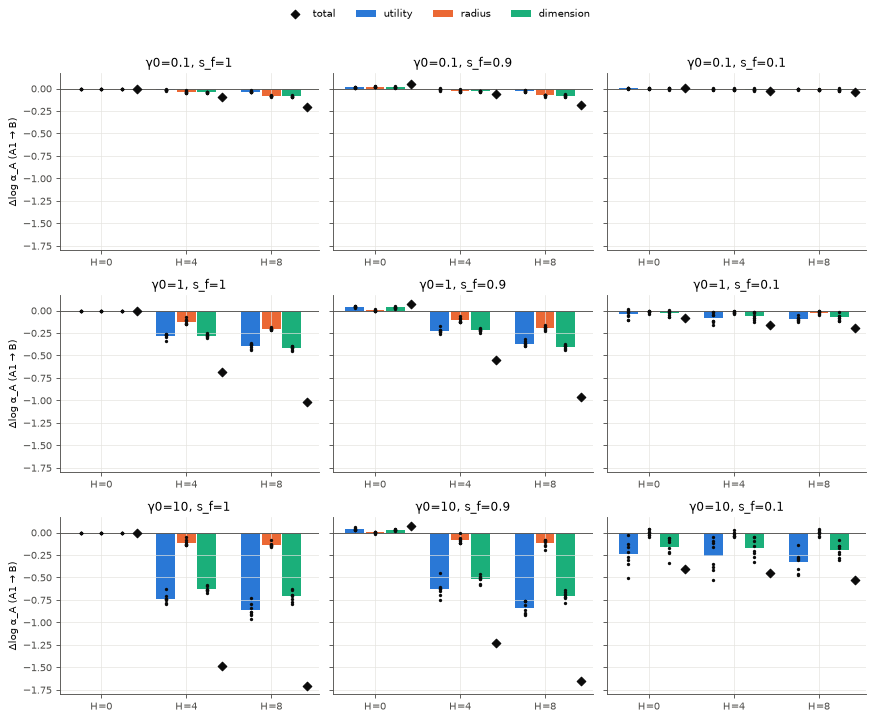

In [18]:
CH = [("utility", BLUE), ("radius", ORANGE), ("dimension", AQUA)]
if HAVE:
    fig, axes = plt.subplots(len(cfg.gammas), len(cfg.s_fs), figsize=(11, 3 * len(cfg.gammas)), sharey=True, squeeze=False)
    for i, g in enumerate(cfg.gammas):
        for j, sf in enumerate(cfg.s_fs):
            ax = axes[i, j]
            for k, h in enumerate(cfg.hammings):
                rs = sel(g, h, sf)
                if not rs: continue
                for ci, (ch, col) in enumerate(CH):
                    v = [r["backward"]["A1_to_B"][ch] for r in rs]; x = k + (ci - 1) * 0.24
                    ax.bar(x, np.mean(v), width=0.22, color=col, label=ch if (i, j, k) == (0, 0, 0) else None)
                    ax.scatter([x] * len(v), v, s=9, color=INK, zorder=3, linewidths=0)
                tot = [r["backward"]["A1_to_B"]["total"] for r in rs]
                ax.scatter([k + 0.42], [np.mean(tot)], marker="D", s=30, color=INK, zorder=4,
                           label="total" if (i, j, k) == (0, 0, 0) else None)
            ax.axhline(0, color=MUTED, linewidth=0.8)
            ax.set_xticks(range(len(cfg.hammings)), [f"H={h}" for h in cfg.hammings])
            ax.set_title(f"γ0={g:g}, s_f={sf:g}")
        axes[i, 0].set_ylabel("Δlog α_A (A1 → B)")
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=4, frameon=False)
    plt.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

**Q2. Behavioural forgetting and relearning.** Test loss on A through A → B → A, seed 0, s_f = 0.9. Each phase is scaled to unit width, because the step counts differ by orders of magnitude across γ₀.

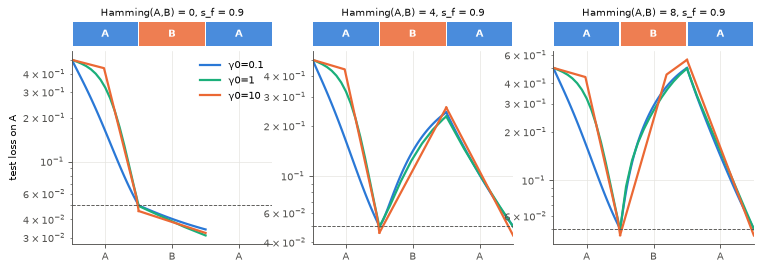

| γ0 | s_f | H | n | forgetting on B, test loss (vs running min) | forgetting on B, test acc (vs running max) | H/P | max |acc forgetting − H/P| over seeds | savings log((1+steps A1)/(1+steps A2)), mean [CI] | savings per seed | raw steps A1 (per seed) | raw steps B | raw steps A2 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | 8 | +0.0000 | +0.0000 | 0.0000 | 0.00e+00 | excluded¹ | — | 1905/1972/2011/2226/1871/2266/1761/1833 | 0/0/0/0/0/0/0/0 | 0/0/0/0/0/0/0/0 |
| 0.1 | 1 | 4 | 8 | +0.2689 | +0.2483 | 0.2500 | 5.42e-03 | +0.643 [+0.521, +0.765] | +0.66 +0.53 +0.80 +0.68 +0.40 +0.86 +0.59 +0.63 | 1905/1972/2011/2226/1871/2266/1761/1833 | 1253/1537/1450/1567/1672/1208/1270/1601 | 986/1157/900/1131/1253/957/978/979 |
| 0.1 | 1 | 8 | 8 | +0.6832 | +0.4990 | 0.5000 | 3.33e-03 | +0.127 [-0.006, +0.260] | +0.04 +0.13 +0.02 +0.42 -0.05 +0.32 +0.05 +0.10 | 1905/1972/2011/2226/1871/2266/1761/1833 | 2337/2117/2305/1784/2373/1984/2158/2001 | 1832/1733/1973/1466/1973/1652/1670/1666 |
| 0.1 | 0.9 | 0 | 8 | -0.0002 | +0.0000 | 0.0000 | 0.00e+00 | +7.588 [+7.513, +7.663] | +7.55 +7.59 +7.61 +7.71 +7.53 +7.73 +7.47 +7.51 | 1905/1972/2011/2226/1871/2266/1761/1833 | 410/535/439/481/422/487/705/667 | 0/0/0/0/0/0/0/0 |
| 0.1 | 0.9 | 4 | 8 | +0.1976 | +0.2269 | 0.2500 | 4.08e-02 | +0.861 [+0.745, +0.977] | +0.84 +0.89 +0.97 +0.98 +0.63 +1.04 +0.75 +0.78 | 1905/1972/2011/2226/1871/2266/1761/1833 | 1226/1435/1538/1386/1645/1178/1261/1675 | 819/810/759/834/1000/797/833/837 |
| 0.1 | 0.9 | 8 | 8 | +0.5132 | +0.4701 | 0.5000 | 5.25e-02 | +0.350 [+0.227, +0.474] | +0.27 +0.43 +0.22 +0.60 +0.16 +0.48 +0.34 +0.29 | 1905/1972/2011/2226/1871/2266/1761/1833 | 2035/2041/2227/1775/2288/2042/2133/1859 | 1456/1281/1612/1216/1598/1395/1247/1371 |
| 0.1 | 0.1 | 0 | 8 | +0.0325 | +0.0140 | 0.0000 | 2.58e-02 | +2.057 [+1.743, +2.371] | +2.26 +1.87 +2.13 +1.89 +2.58 +2.51 +1.62 +1.60 | 1905/1972/2011/2226/1871/2266/1761/1833 | 1593/1681/1389/1294/1340/1438/1550/1516 | 198/304/239/334/141/183/348/369 |
| 0.1 | 0.1 | 4 | 8 | +0.0566 | +0.0234 | 0.2500 | 2.50e-01 | +1.857 [+0.886, +2.828] | +1.62 +1.29 +1.15 +1.55 +4.64 +1.94 +1.59 +1.07 | 1905/1972/2011/2226/1871/2266/1761/1833 | 1346/1840/1981/1395/1443/1651/1734/1735 | 375/543/634/472/17/325/360/626 |
| 0.1 | 0.1 | 8 | 8 | +0.0618 | +0.0280 | 0.5000 | 4.93e-01 | +1.439 [+1.098, +1.779] | +1.45 +1.46 +1.16 +2.22 +0.96 +1.71 +1.50 +1.04 | 1905/1972/2011/2226/1871/2266/1761/1833 | 1370/1541/1630/1326/1495/1532/1546/1850 | 448/457/628/240/716/407/391/647 |
| 1 | 1 | 0 | 8 | +0.0000 | +0.0000 | 0.0000 | 0.00e+00 | excluded¹ | — | 350/351/331/378/350/373/330/327 | 0/0/0/0/0/0/0/0 | 0/0/0/0/0/0/0/0 |
| 1 | 1 | 4 | 8 | +0.2402 | +0.2488 | 0.2500 | 7.08e-03 | +0.924 [+0.812, +1.037] | +1.06 +0.78 +0.97 +0.98 +0.70 +1.10 +0.93 +0.87 | 350/351/331/378/350/373/330/327 | 156/212/200/194/225/166/185/215 | 120/160/125/141/173/124/130/136 |
| 1 | 1 | 8 | 8 | +0.6353 | +0.4999 | 0.5000 | 8.33e-04 | +0.342 [+0.225, +0.458] | +0.30 +0.30 +0.16 +0.60 +0.25 +0.47 +0.36 +0.29 | 350/351/331/378/350/373/330/327 | 331/310/324/247/319/280/290/291 | 260/260/283/206/272/233/229/244 |
| 1 | 0.9 | 0 | 8 | -0.0043 | -0.0001 | 0.0000 | 4.17e-04 | +5.856 [+5.810, +5.902] | +5.86 +5.86 +5.81 +5.94 +5.86 +5.92 +5.80 +5.79 | 350/351/331/378/350/373/330/327 | 37/47/38/43/43/38/61/57 | 0/0/0/0/0/0/0/0 |
| 1 | 0.9 | 4 | 8 | +0.1758 | +0.2275 | 0.2500 | 3.87e-02 | +1.254 [+1.164, +1.345] | +1.31 +1.22 +1.27 +1.43 +1.07 +1.34 +1.23 +1.17 | 350/351/331/378/350/373/330/327 | 157/202/205/158/212/158/170/207 | 94/103/92/90/119/97/96/101 |
| 1 | 0.9 | 8 | 8 | +0.4757 | +0.4830 | 0.5000 | 4.42e-02 | +0.722 [+0.624, +0.820] | +0.72 +0.76 +0.55 +0.93 +0.60 +0.77 +0.77 +0.68 | 350/351/331/378/350/373/330/327 | 281/287/282/229/295/269/268/250 | 170/163/191/149/192/172/152/165 |
| 1 | 0.1 | 0 | 8 | +0.0087 | +0.0059 | 0.0000 | 1.92e-02 | +4.241 [+3.076, +5.405] | +5.86 +3.09 +3.03 +3.63 +5.86 +5.92 +2.81 +3.71 | 350/351/331/378/350/373/330/327 | 177/187/184/158/160/163/179/180 | 0/15/15/9/0/0/19/7 |
| 1 | 0.1 | 4 | 8 | +0.0198 | +0.0053 | 0.2500 | 2.50e-01 | +3.760 [+2.259, +5.262] | +5.86 +2.37 +2.00 +2.68 +5.86 +5.92 +3.24 +2.16 | 350/351/331/378/350/373/330/327 | 158/217/232/175/166/182/195/201 | 0/32/44/25/0/0/12/37 |
| 1 | 0.1 | 8 | 8 | +0.0210 | +0.0086 | 0.5000 | 4.99e-01 | +2.786 [+2.236, +3.336] | +2.97 +2.82 +2.31 +3.74 +2.12 +3.73 +2.47 +2.13 | 350/351/331/378/350/373/330/327 | 178/180/200/163/183/179/185/229 | 17/20/32/8/41/8/27/38 |
| 10 | 1 | 0 | 8 | +0.0000 | +0.0000 | 0.0000 | 0.00e+00 | excluded¹ | — | 52/51/47/54/51/54/49/48 | 0/0/0/0/0/0/0/0 | 0/0/0/0/0/0/0/0 |
| 10 | 1 | 4 | 8 | +0.2611 | +0.2461 | 0.2500 | 7.08e-03 | +1.132 [+0.949, +1.314] | +1.33 +0.86 +1.10 +1.30 +0.77 +1.37 +1.20 +1.12 | 52/51/47/54/51/54/49/48 | 15/24/28/18/26/16/20/23 | 13/21/15/14/23/13/14/15 |
| 10 | 1 | 8 | 8 | +0.6785 | +0.4995 | 0.5000 | 3.75e-03 | +0.430 [+0.216, +0.643] | +0.31 +0.29 +0.02 +0.79 +0.34 +0.71 +0.62 +0.37 | 52/51/47/54/51/54/49/48 | 45/39/45/27/43/28/33/34 | 38/38/46/24/36/26/26/33 |
| 10 | 0.9 | 0 | 8 | -0.0158 | -0.0002 | 0.0000 | 1.67e-03 | +3.945 [+3.903, +3.988] | +3.97 +3.95 +3.87 +4.01 +3.95 +4.01 +3.91 +3.89 | 52/51/47/54/51/54/49/48 | 3/5/4/4/4/4/5/5 | 0/0/0/0/0/0/0/0 |
| 10 | 0.9 | 4 | 8 | +0.2034 | +0.2323 | 0.2500 | 4.88e-02 | +1.585 [+1.499, +1.672] | +1.57 +1.55 +1.57 +1.81 +1.47 +1.61 +1.61 +1.49 | 52/51/47/54/51/54/49/48 | 18/23/26/14/24/17/17/23 | 10/10/9/8/11/10/9/10 |
| 10 | 0.9 | 8 | 8 | +0.5367 | +0.4882 | 0.5000 | 2.83e-02 | +1.080 [+0.978, +1.182] | +1.08 +1.18 +0.93 +1.30 +0.96 +1.12 +1.08 +1.00 | 52/51/47/54/51/54/49/48 | 36/30/37/24/40/31/29/28 | 17/15/18/14/19/17/16/17 |
| 10 | 0.1 | 0 | 8 | +0.0147 | +0.0093 | 0.0000 | 2.67e-02 | +3.100 [+2.604, +3.596] | +3.97 +2.56 +2.77 +2.91 +3.26 +4.01 +2.53 +2.79 | 52/51/47/54/51/54/49/48 | 20/22/23/18/19/18/21/21 | 0/3/2/2/1/0/3/2 |
| 10 | 0.1 | 4 | 8 | +0.0278 | +0.0084 | 0.2500 | 2.51e-01 | +2.894 [+2.254, +3.534] | +3.28 +2.34 +2.08 +2.40 +3.95 +4.01 +2.81 +2.28 | 52/51/47/54/51/54/49/48 | 18/26/29/21/20/20/23/23 | 1/4/5/4/0/0/2/4 |
| 10 | 0.1 | 8 | 8 | +0.0287 | +0.0122 | 0.5000 | 5.00e-01 | +2.698 [+2.406, +2.990] | +2.87 +2.85 +2.48 +2.91 +2.34 +3.31 +2.53 +2.28 | 52/51/47/54/51/54/49/48 | 21/21/25/18/21/19/21/27 | 2/2/3/2/4/1/3/4 |

¹ Identity cell (H0, s_f 1.0): B and A2 take 0 steps, so the savings log ratio is log(1+steps A1) by construction. It is excluded from every savings summary.

accuracy forgetting vs H/P: max deviation over all cells and seeds = 5.00e-01


In [19]:
ACC_DEV = []
if HAVE:
    SF = 0.9 if 0.9 in cfg.s_fs else cfg.s_fs[0]
    fig = plt.figure(figsize=(11, 3.6))
    gs = fig.add_gridspec(2, len(cfg.hammings), height_ratios=[0.12, 1], hspace=0.05)
    for k, h in enumerate(cfg.hammings):
        stream_strip(fig.add_subplot(gs[0, k]), h, SF)
        ax = fig.add_subplot(gs[1, k])
        for g in cfg.gammas:
            rs = sel(g, h, SF)
            r = next((x for x in rs if x["spec"]["seed"] == S0), None)
            if r is None: continue
            for p, ph in enumerate(("A1", "B", "A2")):
                rec = r["trajectory"][ph]; st = np.array([q["step"] for q in rec], float)
                x = p + (st / st.max() if st.max() > 0 else np.zeros_like(st))
                ax.plot(x, [q["A_test_loss"] for q in rec], color=GAMMA_COL[g], label=f"γ0={g:g}" if p == 0 else None)
        ax.axhline(cfg.target_loss, color=MUTED, linewidth=0.8, linestyle="--")
        ax.set_yscale("log"); ax.set_xlim(0, 3); ax.set_xticks([0.5, 1.5, 2.5], ["A", "B", "A"])
        if k == 0: ax.set_ylabel("test loss on A"); ax.legend(frameon=False)
    plt.show()
    rows = []
    for g in cfg.gammas:
        for sf in cfg.s_fs:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs: continue
                fl = [r["behaviour"]["forget_B_loss"]["forgetting"] for r in rs]
                fa = [r["behaviour"]["forget_B_acc"]["forgetting"] for r in rs]
                dev = max(abs(x - h / cfg.P) for x in fa); ACC_DEV.append((g, sf, h, dev))
                sv = [r["behaviour"]["savings"] for r in rs]
                stp = lambda p: "/".join(str(r["behaviour"]["steps"][p]) for r in rs)
                ident = IDENTITY(h, sf)
                rows.append([f"{g:g}", f"{sf:g}", h, len(rs), f"{np.mean(fl):+.4f}", f"{np.mean(fa):+.4f}", f"{h / cfg.P:.4f}", f"{dev:.2e}",
                             "excluded¹" if ident else mci(sv), "—" if ident else " ".join(f"{x:+.2f}" for x in sv),
                             stp("A1"), stp("B"), stp("A2")])
    md_table(["γ0", "s_f", "H", "n", "forgetting on B, test loss (vs running min)", "forgetting on B, test acc (vs running max)",
              "H/P", "max |acc forgetting − H/P| over seeds",
              "savings log((1+steps A1)/(1+steps A2)), mean [CI]", "savings per seed", "raw steps A1 (per seed)", "raw steps B", "raw steps A2"], rows)
    display(Markdown("¹ Identity cell (H0, s_f 1.0): B and A2 take 0 steps, so the savings log ratio is "
                     "log(1+steps A1) by construction. It is excluded from every savings summary."))
    print(f"accuracy forgetting vs H/P: max deviation over all cells and seeds = {max(d for *_, d in ACC_DEV):.2e}")

**Q2b. Bottleneck probe: the behavioural counterpart of capacity.** The frozen hidden layer
is projected to `cfg.bottleneck_n` units by a fixed random projection (drawn once per seed),
and a fresh width-n readout is fitted by full-batch GD (μP scaling, lr·s² = lr0/n at every γ₀)
for a fixed `cfg.refit_steps` steps, then scored on A's test points. n was calibrated once on
the init representation at FULL scale so that init accuracy ≈ 0.75, then frozen
(`docs/reference/choices-register.md`). The init column is identical across γ₀.

Secondary: the **full-width refit loss** (fresh readout on all N units, same budget). Its
accuracy is not shown: it saturates (0.998 at init in the 11-09 QUICK run).

In [20]:
RB = ("init", "A1", "B", "A2")
if HAVE:
    print(f"bottleneck width n = {cfg.bottleneck_n}; budget {cfg.refit_steps} steps; checkpoints also at {L.REFIT_CHECKPOINTS}")
    rows = []
    for g, sf, h in CELLS:
        rs = sel(g, h, sf)
        if not rs: continue
        bl = lambda b, m: np.mean([r["bottleneck"][b][m] for r in rs])
        dacc = [r["bottleneck"]["B"]["acc"] - r["bottleneck"]["A1"]["acc"] for r in rs]
        rows.append([f"{g:g}", f"{sf:g}", h]
                    + [f"{bl(b, 'acc'):.3f}" for b in RB] + [mci(dacc)]
                    + [f"{bl(b, 'loss'):.4f}" for b in RB]
                    + [" / ".join(f"{np.mean([r['refit'][b]['loss'] for r in rs]):.4f}" for b in RB)])
    md_table(["γ0", "s_f", "H", "bottleneck test acc: init", "after A", "after B", "after A again",
              "Δ acc A→B, mean [CI]", "bottleneck test loss: init", "after A", "after B", "after A again",
              "full-width refit loss init / A / B / A (secondary)"], rows)

bottleneck width n = 16; budget 2000 steps; checkpoints also at (100, 500)


| γ0 | s_f | H | bottleneck test acc: init | after A | after B | after A again | Δ acc A→B, mean [CI] | bottleneck test loss: init | after A | after B | after A again | full-width refit loss init / A / B / A (secondary) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | 0.786 | 0.845 | 0.845 | 0.845 | +0.000 [+0.000, +0.000] | 0.3046 | 0.2422 | 0.2422 | 0.2422 | 0.0981 / 0.0466 / 0.0466 / 0.0466 |
| 0.1 | 1 | 4 | 0.786 | 0.845 | 0.823 | 0.853 | -0.023 [-0.030, -0.016] | 0.3046 | 0.2422 | 0.2686 | 0.2364 | 0.0981 / 0.0466 / 0.0630 / 0.0384 |
| 0.1 | 1 | 8 | 0.786 | 0.845 | 0.795 | 0.848 | -0.050 [-0.066, -0.035] | 0.3046 | 0.2422 | 0.2935 | 0.2398 | 0.0981 / 0.0466 / 0.0839 / 0.0410 |
| 0.1 | 0.9 | 0 | 0.786 | 0.845 | 0.855 | 0.855 | +0.009 [+0.005, +0.014] | 0.3046 | 0.2422 | 0.2324 | 0.2324 | 0.0981 / 0.0466 / 0.0396 / 0.0396 |
| 0.1 | 0.9 | 4 | 0.786 | 0.845 | 0.830 | 0.851 | -0.015 [-0.022, -0.008] | 0.3046 | 0.2422 | 0.2599 | 0.2376 | 0.0981 / 0.0466 / 0.0571 / 0.0385 |
| 0.1 | 0.9 | 8 | 0.786 | 0.845 | 0.800 | 0.849 | -0.046 [-0.059, -0.032] | 0.3046 | 0.2422 | 0.2892 | 0.2405 | 0.0981 / 0.0466 / 0.0804 / 0.0421 |
| 0.1 | 0.1 | 0 | 0.786 | 0.845 | 0.845 | 0.850 | -0.001 [-0.004, +0.003] | 0.3046 | 0.2422 | 0.2419 | 0.2376 | 0.0981 / 0.0466 / 0.0451 / 0.0415 |
| 0.1 | 0.1 | 4 | 0.786 | 0.845 | 0.839 | 0.848 | -0.007 [-0.013, -0.000] | 0.3046 | 0.2422 | 0.2480 | 0.2387 | 0.0981 / 0.0466 / 0.0490 / 0.0423 |
| 0.1 | 0.1 | 8 | 0.786 | 0.845 | 0.837 | 0.847 | -0.008 [-0.014, -0.003] | 0.3046 | 0.2422 | 0.2521 | 0.2412 | 0.0981 / 0.0466 / 0.0509 / 0.0425 |
| 1 | 1 | 0 | 0.786 | 0.979 | 0.979 | 0.979 | +0.000 [+0.000, +0.000] | 0.3046 | 0.0884 | 0.0884 | 0.0884 | 0.0981 / 0.0176 / 0.0176 / 0.0176 |
| 1 | 1 | 4 | 0.786 | 0.979 | 0.881 | 0.983 | -0.098 [-0.121, -0.074] | 0.3046 | 0.0884 | 0.1979 | 0.0898 | 0.0981 / 0.0176 / 0.0456 / 0.0142 |
| 1 | 1 | 8 | 0.786 | 0.979 | 0.796 | 0.981 | -0.183 [-0.220, -0.145] | 0.3046 | 0.0884 | 0.2994 | 0.0922 | 0.0981 / 0.0176 / 0.0728 / 0.0156 |
| 1 | 0.9 | 0 | 0.786 | 0.979 | 0.984 | 0.984 | +0.005 [+0.002, +0.007] | 0.3046 | 0.0884 | 0.0808 | 0.0808 | 0.0981 / 0.0176 / 0.0152 / 0.0152 |
| 1 | 0.9 | 4 | 0.786 | 0.979 | 0.917 | 0.982 | -0.061 [-0.090, -0.033] | 0.3046 | 0.0884 | 0.1640 | 0.0913 | 0.0981 / 0.0176 / 0.0377 / 0.0142 |
| 1 | 0.9 | 8 | 0.786 | 0.979 | 0.802 | 0.980 | -0.176 [-0.204, -0.149] | 0.3046 | 0.0884 | 0.2823 | 0.0951 | 0.0981 / 0.0176 / 0.0699 / 0.0154 |
| 1 | 0.1 | 0 | 0.786 | 0.979 | 0.977 | 0.979 | -0.002 [-0.009, +0.005] | 0.3046 | 0.0884 | 0.0950 | 0.0927 | 0.0981 / 0.0176 / 0.0192 / 0.0181 |
| 1 | 0.1 | 4 | 0.786 | 0.979 | 0.974 | 0.978 | -0.005 [-0.014, +0.005] | 0.3046 | 0.0884 | 0.1037 | 0.0967 | 0.0981 / 0.0176 / 0.0219 / 0.0188 |
| 1 | 0.1 | 8 | 0.786 | 0.979 | 0.963 | 0.970 | -0.016 [-0.029, -0.003] | 0.3046 | 0.0884 | 0.1133 | 0.1027 | 0.0981 / 0.0176 / 0.0224 / 0.0189 |
| 10 | 1 | 0 | 0.786 | 0.998 | 0.998 | 0.998 | +0.000 [+0.000, +0.000] | 0.3046 | 0.0375 | 0.0375 | 0.0375 | 0.0981 / 0.0119 / 0.0119 / 0.0119 |
| 10 | 1 | 4 | 0.786 | 0.998 | 0.894 | 1.000 | -0.105 [-0.126, -0.083] | 0.3046 | 0.0375 | 0.1764 | 0.0423 | 0.0981 / 0.0119 / 0.0335 / 0.0085 |
| 10 | 1 | 8 | 0.786 | 0.998 | 0.810 | 1.000 | -0.189 [-0.249, -0.128] | 0.3046 | 0.0375 | 0.2760 | 0.0376 | 0.0981 / 0.0119 / 0.0408 / 0.0088 |
| 10 | 0.9 | 0 | 0.786 | 0.998 | 0.999 | 0.999 | +0.001 [-0.000, +0.002] | 0.3046 | 0.0375 | 0.0340 | 0.0340 | 0.0981 / 0.0119 / 0.0105 / 0.0105 |
| 10 | 0.9 | 4 | 0.786 | 0.998 | 0.932 | 1.000 | -0.067 [-0.105, -0.028] | 0.3046 | 0.0375 | 0.1442 | 0.0431 | 0.0981 / 0.0119 / 0.0247 / 0.0094 |
| 10 | 0.9 | 8 | 0.786 | 0.998 | 0.831 | 1.000 | -0.168 [-0.196, -0.139] | 0.3046 | 0.0375 | 0.2618 | 0.0427 | 0.0981 / 0.0119 / 0.0397 / 0.0103 |
| 10 | 0.1 | 0 | 0.786 | 0.998 | 0.993 | 0.997 | -0.005 [-0.013, +0.003] | 0.3046 | 0.0375 | 0.0524 | 0.0448 | 0.0981 / 0.0119 / 0.0147 / 0.0127 |
| 10 | 0.1 | 4 | 0.786 | 0.998 | 0.997 | 0.998 | -0.002 [-0.005, +0.001] | 0.3046 | 0.0375 | 0.0562 | 0.0449 | 0.0981 / 0.0119 / 0.0162 / 0.0129 |
| 10 | 0.1 | 8 | 0.786 | 0.998 | 0.992 | 0.998 | -0.006 [-0.015, +0.002] | 0.3046 | 0.0375 | 0.0653 | 0.0495 | 0.0981 / 0.0119 / 0.0173 / 0.0141 |

**Q3. Forward transfer.** Does the geometric change A made on B's manifolds go with behavioural forward transfer? **Specific FT_geo** = Δlog α_{y_B} − mean_k Δlog α_{y\*_k}, init → after A, against K = 4 neutral probes (balanced, s_r(y\*_k, y_A) = 0, fixed per seed). **Specific FT_beh** = FT_beh(cell) − FT_beh(H8, s_f 0.1), paired per seed within γ₀ (warm-start baseline), with FT_beh = log((1+steps fresh)/(1+steps B)). The anchored y\* (s_r = +0.5 to y_A) is kept as one labelled column. Hamming 0 with s_f 1.0 is excluded. Panels are stratified by s_f; nothing is pooled.

| seed | s_r(y* anchored, y_A) | s_r(y*_k neutral, y_A), k = 0..3 |
|---|---|---|
| 8 | +0.500 | +0.000 +0.000 +0.000 +0.000 |
| 9 | +0.500 | +0.000 +0.000 +0.000 +0.000 |
| 10 | +0.500 | +0.000 +0.000 +0.000 +0.000 |
| 11 | +0.500 | +0.000 +0.000 +0.000 +0.000 |
| 12 | +0.500 | +0.000 +0.000 +0.000 +0.000 |
| 13 | +0.500 | +0.000 +0.000 +0.000 +0.000 |
| 14 | +0.500 | +0.000 +0.000 +0.000 +0.000 |
| 15 | +0.500 | +0.000 +0.000 +0.000 +0.000 |

neutral probes: s_r(y*_k, y_A) = 0 for every k and seed: True


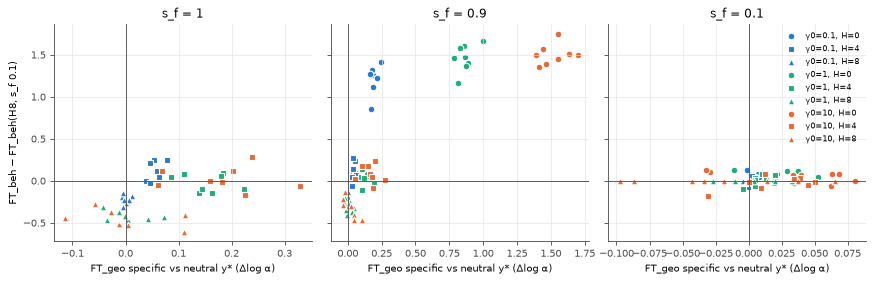

| γ0 | s_f | H | Δlog α_{y_B} total | utility | radius | dimension | mean Δlog α_{y*_k} (neutral) | FT_geo specific (neutral), mean [CI] | FT_geo specific, anchored y* (comparison) | FT_beh, mean [CI] | FT_beh specific (− H8, s_f 0.1), mean [CI] | zero-shot loss on B | raw steps B (per seed) | raw steps fresh B |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 4 | +0.068 | +0.005 | +0.029 | +0.034 | +0.011 | +0.056 [+0.045, +0.067] | -0.003 | +0.269 [+0.186, +0.351] | +0.098 [-0.008, +0.204] | 0.437 | 1253/1537/1450/1567/1672/1208/1270/1601 | 1672/1888/2185/1988/1917/1802/1522/2140 |
| 0.1 | 1 | 8 | +0.012 | -0.004 | +0.006 | +0.010 | +0.011 | +0.000 [-0.005, +0.006] | -0.059 | -0.055 [-0.086, -0.024] | -0.226 [-0.269, -0.182] | 0.825 | 2337/2117/2305/1784/2373/1984/2158/2001 | 2320/1932/2080/1743/2243/1829/2137/1871 |
| 0.1 | 0.9 | 0 | +0.199 | +0.027 | +0.079 | +0.092 | +0.008 | +0.190 [+0.167, +0.214] | +0.142 | +1.391 [+1.247, +1.534] | +1.220 [+1.077, +1.363] | 0.084 | 410/535/439/481/422/487/705/667 | 1814/2238/1921/2171/1738/2324/2050/2193 |
| 0.1 | 0.9 | 4 | +0.052 | +0.004 | +0.022 | +0.026 | +0.008 | +0.044 [+0.034, +0.053] | -0.004 | +0.284 [+0.205, +0.363] | +0.113 [+0.025, +0.201] | 0.406 | 1226/1435/1538/1386/1645/1178/1261/1675 | 1636/1849/2081/1978/1784/1737/1634/2365 |
| 0.1 | 0.9 | 8 | +0.010 | -0.001 | +0.003 | +0.008 | +0.008 | +0.001 [-0.001, +0.004] | -0.047 | -0.013 [-0.059, +0.032] | -0.184 [-0.223, -0.145] | 0.760 | 2035/2041/2227/1775/2288/2042/2133/1859 | 2087/1832/2168/1893/2298/1981/2182/1752 |
| 0.1 | 0.1 | 0 | +0.004 | +0.001 | +0.001 | +0.002 | +0.001 | +0.004 [+0.001, +0.006] | +0.002 | +0.226 [+0.201, +0.250] | +0.055 [+0.022, +0.088] | 0.490 | 1593/1681/1389/1294/1340/1438/1550/1516 | 2013/2087/1698/1721/1678/1745/1972/1870 |
| 0.1 | 0.1 | 4 | +0.002 | +0.000 | +0.000 | +0.001 | +0.001 | +0.001 [+0.000, +0.003] | +0.000 | +0.149 [+0.106, +0.191] | -0.022 [-0.054, +0.010] | 0.536 | 1346/1840/1981/1395/1443/1651/1734/1735 | 1594/2073/2222/1719/1753/1874/2105/1848 |
| 0.1 | 0.1 | 8 | +0.000 | -0.001 | +0.000 | +0.001 | +0.001 | -0.000 [-0.003, +0.003] | -0.001 | +0.171 [+0.121, +0.221] | baseline (0) | 0.584 | 1370/1541/1630/1326/1495/1532/1546/1850 | 1626/1819/1912/1766/1723/1778/1914/2001 |
| 1 | 1 | 4 | +0.269 | +0.029 | +0.082 | +0.159 | +0.116 | +0.154 [+0.117, +0.190] | -0.014 | +0.556 [+0.481, +0.632] | -0.028 [-0.114, +0.059] | 0.423 | 156/212/200/194/225/166/185/215 | 310/346/360/347/343/324/307/364 |
| 1 | 1 | 8 | +0.117 | -0.024 | +0.039 | +0.102 | +0.116 | +0.002 [-0.031, +0.034] | -0.166 | +0.173 [+0.129, +0.216] | -0.411 [-0.460, -0.363] | 0.799 | 331/310/324/247/319/280/290/291 | 390/350/357/318/390/326/364/345 |
| 1 | 0.9 | 0 | +0.951 | +0.280 | +0.236 | +0.435 | +0.088 | +0.863 [+0.811, +0.916] | +0.706 | +2.050 [+1.907, +2.194] | +1.466 [+1.334, +1.599] | 0.081 | 37/47/38/43/43/38/61/57 | 340/379/316/369/334/380/361/365 |
| 1 | 0.9 | 4 | +0.221 | +0.024 | +0.067 | +0.131 | +0.088 | +0.133 [+0.105, +0.161] | -0.025 | +0.618 [+0.536, +0.699] | +0.034 [-0.032, +0.099] | 0.400 | 157/202/205/158/212/158/170/207 | 306/353/358/344/334/316/320/385 |
| 1 | 0.9 | 8 | +0.095 | -0.017 | +0.028 | +0.085 | +0.088 | +0.007 [-0.012, +0.027] | -0.150 | +0.275 [+0.229, +0.322] | -0.309 [-0.364, -0.254] | 0.738 | 281/287/282/229/295/269/268/250 | 368/347/365/334/385/343/372/330 |
| 1 | 0.1 | 0 | +0.025 | +0.001 | +0.009 | +0.015 | +0.001 | +0.024 [+0.008, +0.040] | +0.016 | +0.659 [+0.614, +0.703] | +0.075 [+0.033, +0.117] | 0.464 | 177/187/184/158/160/163/179/180 | 352/369/323/318/317/337/342/330 |
| 1 | 0.1 | 4 | +0.010 | -0.002 | +0.001 | +0.011 | +0.001 | +0.009 [+0.002, +0.016] | +0.001 | +0.587 [+0.524, +0.650] | +0.003 [-0.050, +0.057] | 0.507 | 158/217/232/175/166/182/195/201 | 308/369/375/326/317/348/366/329 |
| 1 | 0.1 | 8 | -0.003 | -0.003 | -0.002 | +0.002 | +0.001 | -0.004 [-0.022, +0.014] | -0.012 | +0.584 [+0.523, +0.645] | baseline (0) | 0.548 | 178/180/200/163/183/179/185/229 | 322/326/334/337/324/331/337/370 |
| 10 | 1 | 4 | +0.570 | +0.012 | +0.149 | +0.410 | +0.387 | +0.183 [+0.109, +0.258] | -0.015 | +0.832 [+0.679, +0.985] | +0.027 [-0.088, +0.143] | 0.427 | 15/24/28/18/26/16/20/23 | 46/50/52/50/50/47/46/52 |
| 10 | 1 | 8 | +0.387 | -0.095 | +0.140 | +0.342 | +0.387 | +0.000 [-0.064, +0.065] | -0.198 | +0.345 [+0.222, +0.467] | -0.459 [-0.545, -0.374] | 0.810 | 45/39/45/27/43/28/33/34 | 55/51/52/47/57/47/52/51 |
| 10 | 0.9 | 0 | +1.832 | +0.622 | +0.248 | +0.962 | +0.314 | +1.518 [+1.426, +1.609] | +1.317 | +2.307 [+2.197, +2.416] | +1.502 [+1.403, +1.601] | 0.077 | 3/5/4/4/4/4/5/5 | 50/55/45/53/49/55/52/52 |
| 10 | 0.9 | 4 | +0.478 | -0.002 | +0.125 | +0.354 | +0.314 | +0.163 [+0.109, +0.218] | -0.037 | +0.887 [+0.740, +1.035] | +0.083 [-0.007, +0.172] | 0.405 | 18/23/26/14/24/17/17/23 | 45/52/52/50/50/46/48/55 |
| 10 | 0.9 | 8 | +0.325 | -0.087 | +0.106 | +0.306 | +0.314 | +0.011 [-0.031, +0.054] | -0.189 | +0.488 [+0.381, +0.595] | -0.316 [-0.419, -0.213] | 0.748 | 36/30/37/24/40/31/29/28 | 54/52/53/49/56/49/54/49 |
| 10 | 0.1 | 0 | +0.029 | -0.021 | +0.015 | +0.035 | -0.007 | +0.036 [-0.001, +0.072] | +0.028 | +0.863 [+0.797, +0.929] | +0.059 [+0.008, +0.109] | 0.466 | 20/22/23/18/19/18/21/21 | 51/53/49/47/47/50/49/48 |
| 10 | 0.1 | 4 | +0.013 | -0.032 | +0.009 | +0.036 | -0.007 | +0.020 [-0.003, +0.043] | +0.013 | +0.780 [+0.695, +0.865] | -0.024 [-0.094, +0.046] | 0.503 | 18/26/29/21/20/20/23/23 | 45/53/54/48/47/51/53/48 |
| 10 | 0.1 | 8 | -0.027 | -0.035 | -0.008 | +0.016 | -0.007 | -0.020 [-0.068, +0.028] | -0.028 | +0.804 [+0.712, +0.897] | baseline (0) | 0.544 | 21/21/25/18/21/19/21/27 | 48/47/49/50/48/49/49/54 |

In [21]:
MARK = dict(zip(cfg.hammings, ["o", "s", "^", "v", "P"]))
BASE_CELL = (8, 0.1)
def ft_beh_spec(r):
    b = [x for x in sel(r["spec"]["gamma"], *BASE_CELL) if x["spec"]["seed"] == r["spec"]["seed"]]
    return r["behaviour"]["FT_beh"] - b[0]["behaviour"]["FT_beh"]
if HAVE:
    srs = sorted({r["spec"]["seed"]: r["relations"] for r in arms}.items())
    md_table(["seed", "s_r(y* anchored, y_A)", "s_r(y*_k neutral, y_A), k = 0..3"],
             [[s, f"{rel['s_r_ystar_A']:+.3f}", " ".join(f"{v:+.3f}" for v in rel["s_r_ystar_neutral_A"].values())] for s, rel in srs])
    print("neutral probes: s_r(y*_k, y_A) = 0 for every k and seed:",
          all(v == 0.0 for r in arms for v in r["relations"]["s_r_ystar_neutral_A"].values()))
if HAVE:
    fig, axes = plt.subplots(1, len(cfg.s_fs), figsize=(11, 3.6), sharey=True)
    for ax, sf in zip(axes, cfg.s_fs):
        for g in cfg.gammas:
            for h in cfg.hammings:
                if h == 0 and sf == 1.0: continue
                rs = sel(g, h, sf)
                ax.scatter([r["forward"]["specific"] for r in rs], [ft_beh_spec(r) for r in rs],
                           color=GAMMA_COL[g], marker=MARK[h], s=36, edgecolors="white", linewidths=1,
                           label=f"γ0={g:g}, H={h}" if sf == cfg.s_fs[-1] else None)
        ax.axhline(0, color=MUTED, linewidth=0.8); ax.axvline(0, color=MUTED, linewidth=0.8)
        ax.set_title(f"s_f = {sf:g}"); ax.set_xlabel("FT_geo specific vs neutral y* (Δlog α)")
    axes[0].set_ylabel("FT_beh − FT_beh(H8, s_f 0.1)"); axes[-1].legend(frameon=False, fontsize=7, loc="best"); plt.tight_layout(); plt.show()
    rows = []
    for g in cfg.gammas:
        for sf in cfg.s_fs:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs or (h == 0 and sf == 1.0): continue
                f = lambda k: np.mean([r["forward"]["total"][k] for r in rs])
                rows.append([f"{g:g}", f"{sf:g}", h, f"{f('total'):+.3f}", f"{f('utility'):+.3f}", f"{f('radius'):+.3f}",
                             f"{f('dimension'):+.3f}", f"{np.mean([r['forward']['ystar_neutral']['mean'] for r in rs]):+.3f}",
                             mci([r['forward']['specific'] for r in rs]),
                             f"{np.mean([r['forward']['specific_anchored'] for r in rs]):+.3f}",
                             mci([r['behaviour']['FT_beh'] for r in rs]),
                             "baseline (0)" if (h, sf) == BASE_CELL else mci([ft_beh_spec(r) for r in rs]),
                             f"{np.mean([r['behaviour']['first_loss']['B'] for r in rs]):.3f}",
                             "/".join(str(r["behaviour"]["steps"]["B"]) for r in rs),
                             "/".join(str(r["behaviour"]["steps"]["freshB"]) for r in rs)])
    md_table(["γ0", "s_f", "H", "Δlog α_{y_B} total", "utility", "radius", "dimension", "mean Δlog α_{y*_k} (neutral)",
              "FT_geo specific (neutral), mean [CI]", "FT_geo specific, anchored y* (comparison)", "FT_beh, mean [CI]",
              "FT_beh specific (− H8, s_f 0.1), mean [CI]",
              "zero-shot loss on B", "raw steps B (per seed)", "raw steps fresh B"], rows)

**Q4. Richness by phase.** Means over cells and seeds for each γ₀. ΔK and ΔK_u are relative to init, on A's fixed probe set. r_t is the weight change within a phase.

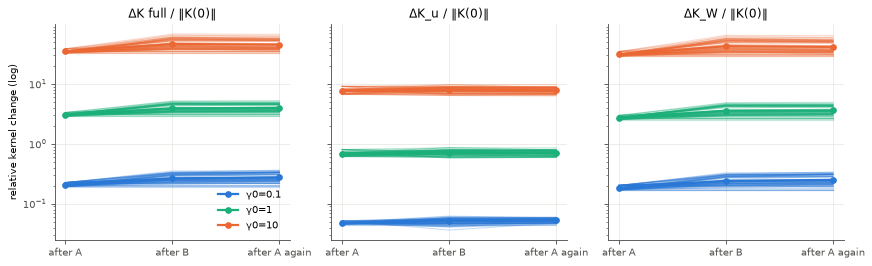

| γ0 | after | weight change from init | r_t (this phase) | ΔK full | ΔK_u | ΔK_W | ‖K_W‖/‖K‖ | CKA(K, y_A y_Aᵀ) | CKA(K_B, y_B y_Bᵀ) |
|---|---|---|---|---|---|---|---|---|---|
| 0.1 | A1 | 0.0226 | 0.0226 | 0.209 | 0.0479 | 0.185 | 0.164 | +0.256 | +0.207 |
| 0.1 | B | 0.0356 | 0.0285 | 0.266 | 0.051 | 0.241 | 0.206 | +0.232 | +0.250 |
| 0.1 | A2 | 0.0338 | 0.0149 | 0.275 | 0.0525 | 0.25 | 0.212 | +0.253 | +0.231 |
| 1 | A1 | 0.161 | 0.161 | 3.08 | 0.69 | 2.73 | 0.729 | +0.333 | +0.230 |
| 1 | B | 0.208 | 0.149 | 3.93 | 0.711 | 3.58 | 0.780 | +0.269 | +0.302 |
| 1 | A2 | 0.201 | 0.069 | 3.96 | 0.706 | 3.61 | 0.782 | +0.305 | +0.265 |
| 10 | A1 | 0.638 | 0.638 | 35 | 7.77 | 31.2 | 0.877 | +0.335 | +0.228 |
| 10 | B | 0.765 | 0.413 | 46.5 | 7.99 | 42.8 | 0.904 | +0.264 | +0.302 |
| 10 | A2 | 0.759 | 0.195 | 45.4 | 7.83 | 41.7 | 0.903 | +0.303 | +0.264 |

**Phase-to-phase kernel change** (from the previous boundary: ‖·_now − ·_prev‖ / ‖K_prev‖_F; alignment = CKA(K_prev, K_now), 1 = same direction). Lines: mean over s_f and seeds per γ₀ × H, identity cell excluded (0 / 1 by construction). Table: per cell, mean [95% CI].

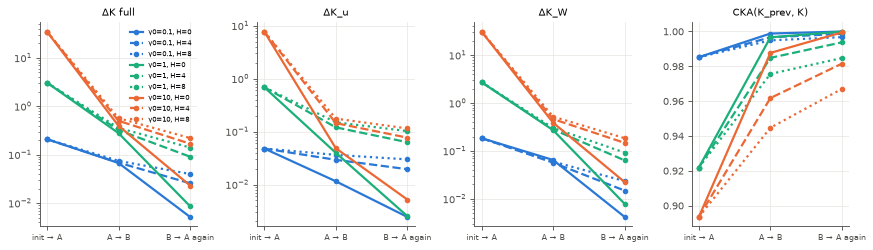

| γ0 | s_f | H | transition | ΔK full | ΔK_u | ΔK_W | CKA(K_prev, K) |
|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | A → B | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 0.1 | 1 | 0 | B → A again | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 0.1 | 1 | 4 | A → B | +0.0471 [+0.0427, +0.0516] | +0.0376 [+0.0347, +0.0405] | +0.0262 [+0.0203, +0.0320] | +0.9958 [+0.9952, +0.9965] |
| 0.1 | 1 | 4 | B → A again | +0.0329 [+0.0309, +0.0348] | +0.0280 [+0.0263, +0.0298] | +0.0168 [+0.0156, +0.0180] | +0.9977 [+0.9974, +0.9979] |
| 0.1 | 1 | 8 | A → B | +0.0606 [+0.0539, +0.0674] | +0.0484 [+0.0463, +0.0505] | +0.0338 [+0.0246, +0.0429] | +0.9930 [+0.9923, +0.9936] |
| 0.1 | 1 | 8 | B → A again | +0.0500 [+0.0478, +0.0521] | +0.0434 [+0.0413, +0.0455] | +0.0245 [+0.0224, +0.0266] | +0.9943 [+0.9937, +0.9949] |
| 0.1 | 0.9 | 0 | A → B | +0.0369 [+0.0289, +0.0449] | +0.0086 [+0.0066, +0.0106] | +0.0328 [+0.0258, +0.0398] | +0.9997 [+0.9996, +0.9998] |
| 0.1 | 0.9 | 0 | B → A again | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 0.1 | 0.9 | 4 | A → B | +0.0568 [+0.0501, +0.0636] | +0.0338 [+0.0309, +0.0367] | +0.0434 [+0.0359, +0.0508] | +0.9966 [+0.9960, +0.9972] |
| 0.1 | 0.9 | 4 | B → A again | +0.0279 [+0.0255, +0.0304] | +0.0226 [+0.0207, +0.0245] | +0.0152 [+0.0125, +0.0179] | +0.9985 [+0.9982, +0.9987] |
| 0.1 | 0.9 | 8 | A → B | +0.0667 [+0.0570, +0.0764] | +0.0433 [+0.0410, +0.0456] | +0.0492 [+0.0367, +0.0618] | +0.9942 [+0.9935, +0.9948] |
| 0.1 | 0.9 | 8 | B → A again | +0.0461 [+0.0435, +0.0486] | +0.0362 [+0.0347, +0.0377] | +0.0264 [+0.0230, +0.0298] | +0.9962 [+0.9959, +0.9965] |
| 0.1 | 0.1 | 0 | A → B | +0.0980 [+0.0892, +0.1067] | +0.0144 [+0.0125, +0.0163] | +0.0968 [+0.0883, +0.1053] | +0.9979 [+0.9976, +0.9981] |
| 0.1 | 0.1 | 0 | B → A again | +0.0103 [+0.0066, +0.0141] | +0.0049 [+0.0034, +0.0064] | +0.0084 [+0.0053, +0.0115] | +0.9999 [+0.9998, +0.9999] |
| 0.1 | 0.1 | 4 | A → B | +0.1017 [+0.0915, +0.1118] | +0.0165 [+0.0142, +0.0188] | +0.1012 [+0.0907, +0.1117] | +0.9975 [+0.9969, +0.9981] |
| 0.1 | 0.1 | 4 | B → A again | +0.0161 [+0.0089, +0.0234] | +0.0078 [+0.0044, +0.0111] | +0.0126 [+0.0066, +0.0186] | +0.9998 [+0.9996, +0.9999] |
| 0.1 | 0.1 | 8 | A → B | +0.0966 [+0.0906, +0.1026] | +0.0172 [+0.0146, +0.0198] | +0.0968 [+0.0907, +0.1029] | +0.9975 [+0.9970, +0.9980] |
| 0.1 | 0.1 | 8 | B → A again | +0.0236 [+0.0161, +0.0310] | +0.0098 [+0.0066, +0.0131] | +0.0194 [+0.0134, +0.0254] | +0.9997 [+0.9995, +0.9998] |
| 1 | 1 | 0 | A → B | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 1 | 1 | 0 | B → A again | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 1 | 1 | 4 | A → B | +0.2297 [+0.2083, +0.2512] | +0.1577 [+0.1469, +0.1684] | +0.1518 [+0.1339, +0.1697] | +0.9782 [+0.9736, +0.9827] |
| 1 | 1 | 4 | B → A again | +0.1428 [+0.1288, +0.1568] | +0.1042 [+0.0994, +0.1090] | +0.0953 [+0.0816, +0.1089] | +0.9882 [+0.9860, +0.9904] |
| 1 | 1 | 8 | A → B | +0.2820 [+0.2623, +0.3016] | +0.2039 [+0.1966, +0.2112] | +0.1736 [+0.1466, +0.2006] | +0.9628 [+0.9586, +0.9670] |
| 1 | 1 | 8 | B → A again | +0.2196 [+0.2097, +0.2295] | +0.1716 [+0.1643, +0.1788] | +0.1331 [+0.1211, +0.1450] | +0.9704 [+0.9675, +0.9734] |
| 1 | 0.9 | 0 | A → B | +0.1211 [+0.0961, +0.1461] | +0.0248 [+0.0191, +0.0306] | +0.1098 [+0.0877, +0.1320] | +0.9995 [+0.9994, +0.9996] |
| 1 | 0.9 | 0 | B → A again | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 1 | 0.9 | 4 | A → B | +0.2693 [+0.2457, +0.2929] | +0.1404 [+0.1282, +0.1525] | +0.2237 [+0.2007, +0.2468] | +0.9842 [+0.9812, +0.9872] |
| 1 | 0.9 | 4 | B → A again | +0.1056 [+0.0971, +0.1142] | +0.0757 [+0.0702, +0.0812] | +0.0728 [+0.0666, +0.0790] | +0.9936 [+0.9926, +0.9946] |
| 1 | 0.9 | 8 | A → B | +0.3148 [+0.2912, +0.3383] | +0.1802 [+0.1726, +0.1878] | +0.2559 [+0.2247, +0.2871] | +0.9729 [+0.9693, +0.9765] |
| 1 | 0.9 | 8 | B → A again | +0.1692 [+0.1601, +0.1782] | +0.1235 [+0.1170, +0.1300] | +0.1139 [+0.1049, +0.1229] | +0.9844 [+0.9822, +0.9865] |
| 1 | 0.1 | 0 | A → B | +0.4368 [+0.4057, +0.4680] | +0.0544 [+0.0448, +0.0641] | +0.4340 [+0.4034, +0.4645] | +0.9937 [+0.9926, +0.9949] |
| 1 | 0.1 | 0 | B → A again | +0.0172 [+0.0024, +0.0321] | +0.0050 [+0.0003, +0.0098] | +0.0157 [+0.0028, +0.0286] | +0.9998 [+0.9995, +1.0000] |
| 1 | 0.1 | 4 | A → B | +0.4668 [+0.4224, +0.5112] | +0.0623 [+0.0514, +0.0732] | +0.4680 [+0.4213, +0.5148] | +0.9921 [+0.9896, +0.9946] |
| 1 | 0.1 | 4 | B → A again | +0.0243 [+0.0039, +0.0446] | +0.0089 [+0.0017, +0.0161] | +0.0227 [+0.0040, +0.0414] | +0.9994 [+0.9988, +1.0000] |
| 1 | 0.1 | 8 | A → B | +0.4748 [+0.4452, +0.5044] | +0.0658 [+0.0542, +0.0775] | +0.4777 [+0.4462, +0.5092] | +0.9911 [+0.9893, +0.9928] |
| 1 | 0.1 | 8 | B → A again | +0.0327 [+0.0219, +0.0435] | +0.0111 [+0.0056, +0.0165] | +0.0305 [+0.0209, +0.0400] | +0.9994 [+0.9990, +0.9997] |
| 10 | 1 | 0 | A → B | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 10 | 1 | 0 | B → A again | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 10 | 1 | 4 | A → B | +0.3626 [+0.3028, +0.4224] | +0.1863 [+0.1700, +0.2027] | +0.2900 [+0.2375, +0.3425] | +0.9490 [+0.9345, +0.9635] |
| 10 | 1 | 4 | B → A again | +0.2610 [+0.2304, +0.2917] | +0.1265 [+0.1188, +0.1342] | +0.2206 [+0.1911, +0.2500] | +0.9645 [+0.9560, +0.9731] |
| 10 | 1 | 8 | A → B | +0.4425 [+0.3986, +0.4863] | +0.2348 [+0.2251, +0.2445] | +0.3503 [+0.2987, +0.4019] | +0.9228 [+0.9129, +0.9327] |
| 10 | 1 | 8 | B → A again | +0.3438 [+0.3299, +0.3578] | +0.1933 [+0.1832, +0.2034] | +0.2731 [+0.2542, +0.2921] | +0.9373 [+0.9321, +0.9426] |
| 10 | 0.9 | 0 | A → B | +0.1370 [+0.1160, +0.1580] | +0.0262 [+0.0212, +0.0312] | +0.1270 [+0.1081, +0.1459] | +0.9986 [+0.9981, +0.9991] |
| 10 | 0.9 | 0 | B → A again | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 10 | 0.9 | 4 | A → B | +0.4122 [+0.3579, +0.4666] | +0.1680 [+0.1506, +0.1854] | +0.3688 [+0.3123, +0.4253] | +0.9616 [+0.9526, +0.9706] |
| 10 | 0.9 | 4 | B → A again | +0.1855 [+0.1680, +0.2031] | +0.0911 [+0.0827, +0.0995] | +0.1624 [+0.1443, +0.1806] | +0.9823 [+0.9788, +0.9859] |
| 10 | 0.9 | 8 | A → B | +0.5074 [+0.4680, +0.5468] | +0.2106 [+0.2004, +0.2207] | +0.4560 [+0.4081, +0.5039] | +0.9408 [+0.9349, +0.9468] |
| 10 | 0.9 | 8 | B → A again | +0.2573 [+0.2360, +0.2786] | +0.1364 [+0.1258, +0.1469] | +0.2211 [+0.2015, +0.2407] | +0.9656 [+0.9600, +0.9711] |
| 10 | 0.1 | 0 | A → B | +0.6517 [+0.5889, +0.7145] | +0.0707 [+0.0583, +0.0831] | +0.6512 [+0.5871, +0.7152] | +0.9767 [+0.9730, +0.9805] |
| 10 | 0.1 | 0 | B → A again | +0.0461 [+0.0166, +0.0755] | +0.0104 [+0.0036, +0.0171] | +0.0447 [+0.0161, +0.0733] | +0.9989 [+0.9980, +0.9998] |
| 10 | 0.1 | 4 | A → B | +0.7276 [+0.6173, +0.8378] | +0.0794 [+0.0647, +0.0940] | +0.7310 [+0.6163, +0.8457] | +0.9747 [+0.9679, +0.9814] |
| 10 | 0.1 | 4 | B → A again | +0.0593 [+0.0212, +0.0975] | +0.0127 [+0.0045, +0.0208] | +0.0596 [+0.0210, +0.0983] | +0.9977 [+0.9959, +0.9996] |
| 10 | 0.1 | 8 | A → B | +0.7527 [+0.6852, +0.8202] | +0.0822 [+0.0693, +0.0950] | +0.7561 [+0.6856, +0.8266] | +0.9704 [+0.9661, +0.9747] |
| 10 | 0.1 | 8 | B → A again | +0.0611 [+0.0409, +0.0812] | +0.0140 [+0.0086, +0.0194] | +0.0605 [+0.0406, +0.0803] | +0.9982 [+0.9972, +0.9991] |

In [22]:
if HAVE:
    PH = ("A1", "B", "A2")
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
    for ax, (k, lab) in zip(axes, [("dK_full", "ΔK full"), ("dK_u", "ΔK_u"), ("dK_W", "ΔK_W")]):
        for g in cfg.gammas:
            rs = sel(g)
            per = np.array([[r["richness"][ph][k] for ph in PH] for r in rs])
            for row in per:
                ax.plot(range(3), row, color=GAMMA_COL[g], alpha=0.25, linewidth=1)
            ax.plot(range(3), per.mean(0), color=GAMMA_COL[g], marker="o", markersize=5, label=f"γ0={g:g}")
        ax.set_yscale("log"); ax.set_xticks(range(3), ["after A", "after B", "after A again"]); ax.set_title(f"{lab} / ‖K(0)‖")
    axes[0].set_ylabel("relative kernel change (log)"); axes[0].legend(frameon=False); plt.tight_layout(); plt.show()
    rows = []
    for g in cfg.gammas:
        rs = sel(g)
        for ph in PH:
            m = lambda k: np.mean([r["richness"][ph][k] for r in rs])
            rows.append([f"{g:g}", ph, f"{m('weight_change'):.3g}", f"{np.mean([r['richness']['r_t'][ph] for r in rs]):.3g}",
                         f"{m('dK_full'):.3g}", f"{m('dK_u'):.3g}", f"{m('dK_W'):.3g}", f"{m('KW_share'):.3f}",
                         f"{m('cka_K_yA'):+.3f}", f"{m('cka_K_yB'):+.3f}"])
    md_table(["γ0", "after", "weight change from init", "r_t (this phase)", "ΔK full", "ΔK_u", "ΔK_W", "‖K_W‖/‖K‖",
              "CKA(K, y_A y_Aᵀ)", "CKA(K_B, y_B y_Bᵀ)"], rows)
    display(Markdown("**Phase-to-phase kernel change** (from the previous boundary: ‖·_now − ·_prev‖ / ‖K_prev‖_F; "
                     "alignment = CKA(K_prev, K_now), 1 = same direction). Lines: mean over s_f and seeds per γ₀ × H, "
                     "identity cell excluded (0 / 1 by construction). Table: per cell, mean [95% CI]."))
    TR = (("A1", "init → A"), ("B", "A → B"), ("A2", "B → A again"))
    fig, axes = plt.subplots(1, 4, figsize=(11, 3.2))
    for ax, (k, lab) in zip(axes, [("dK_full_step", "ΔK full"), ("dK_u_step", "ΔK_u"), ("dK_W_step", "ΔK_W"), ("align_step", "CKA(K_prev, K)")]):
        for g in cfg.gammas:
            for hi, h in enumerate(cfg.hammings):
                rs = [r for r in sel(g, h) if not IDENTITY(h, r["spec"]["s_f"])]
                if rs: ax.plot(range(3), [np.mean([r["richness"][ph][k] for r in rs]) for ph, _ in TR], color=GAMMA_COL[g],
                               linestyle=["-", "--", ":", "-."][hi], marker="o", markersize=4,
                               label=f"γ0={g:g}, H={h}" if k == "dK_full_step" else None)
        if k != "align_step": ax.set_yscale("log")
        ax.set_xticks(range(3), [t for _, t in TR], fontsize=7); ax.set_title(lab, fontsize=9)
    axes[0].legend(frameon=False, fontsize=6); plt.tight_layout(); plt.show()
    rows = []
    for g, sf, h in CELLS:
        rs = sel(g, h, sf)
        if not rs: continue
        for ph, lab in TR[1:]:
            rows.append([f"{g:g}", f"{sf:g}", h, lab] + [mci([r["richness"][ph][k] for r in rs], 4) for k in
                                                         ("dK_full_step", "dK_u_step", "dK_W_step", "align_step")])
    md_table(["γ0", "s_f", "H", "transition", "ΔK full", "ΔK_u", "ΔK_W", "CKA(K_prev, K)"], rows)

**Q5. Centre correlation ρ_c on A's manifolds (signed, normalised), by boundary.** The `glue`-convention value is in a separate table only: it depends on the anchor norm and is not a direction measure.

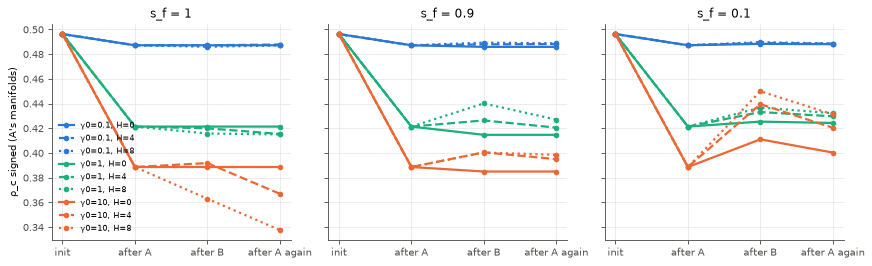

| γ0 | s_f | H | ρ_c signed: init | after A | after B | after A again |
|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | +0.496 [+0.488, +0.505] | +0.487 [+0.478, +0.496] | +0.487 [+0.478, +0.496] | +0.487 [+0.478, +0.496] |
| 0.1 | 1 | 4 | +0.496 [+0.488, +0.505] | +0.487 [+0.478, +0.496] | +0.487 [+0.479, +0.496] | +0.488 [+0.479, +0.496] |
| 0.1 | 1 | 8 | +0.496 [+0.488, +0.505] | +0.487 [+0.478, +0.496] | +0.486 [+0.477, +0.495] | +0.487 [+0.479, +0.496] |
| 0.1 | 0.9 | 0 | +0.496 [+0.488, +0.505] | +0.487 [+0.478, +0.496] | +0.486 [+0.478, +0.494] | +0.486 [+0.478, +0.494] |
| 0.1 | 0.9 | 4 | +0.496 [+0.488, +0.505] | +0.487 [+0.478, +0.496] | +0.488 [+0.479, +0.496] | +0.488 [+0.480, +0.497] |
| 0.1 | 0.9 | 8 | +0.496 [+0.488, +0.505] | +0.487 [+0.478, +0.496] | +0.489 [+0.480, +0.498] | +0.489 [+0.480, +0.498] |
| 0.1 | 0.1 | 0 | +0.496 [+0.488, +0.505] | +0.487 [+0.478, +0.496] | +0.488 [+0.480, +0.497] | +0.488 [+0.480, +0.496] |
| 0.1 | 0.1 | 4 | +0.496 [+0.488, +0.505] | +0.487 [+0.478, +0.496] | +0.489 [+0.481, +0.498] | +0.489 [+0.480, +0.497] |
| 0.1 | 0.1 | 8 | +0.496 [+0.488, +0.505] | +0.487 [+0.478, +0.496] | +0.490 [+0.481, +0.498] | +0.489 [+0.480, +0.497] |
| 1 | 1 | 0 | +0.496 [+0.488, +0.505] | +0.421 [+0.413, +0.430] | +0.421 [+0.413, +0.430] | +0.421 [+0.413, +0.430] |
| 1 | 1 | 4 | +0.496 [+0.488, +0.505] | +0.421 [+0.413, +0.430] | +0.420 [+0.411, +0.429] | +0.415 [+0.408, +0.423] |
| 1 | 1 | 8 | +0.496 [+0.488, +0.505] | +0.421 [+0.413, +0.430] | +0.416 [+0.406, +0.425] | +0.415 [+0.406, +0.424] |
| 1 | 0.9 | 0 | +0.496 [+0.488, +0.505] | +0.421 [+0.413, +0.430] | +0.415 [+0.407, +0.423] | +0.415 [+0.407, +0.423] |
| 1 | 0.9 | 4 | +0.496 [+0.488, +0.505] | +0.421 [+0.413, +0.430] | +0.426 [+0.418, +0.435] | +0.421 [+0.414, +0.427] |
| 1 | 0.9 | 8 | +0.496 [+0.488, +0.505] | +0.421 [+0.413, +0.430] | +0.440 [+0.432, +0.449] | +0.427 [+0.417, +0.437] |
| 1 | 0.1 | 0 | +0.496 [+0.488, +0.505] | +0.421 [+0.413, +0.430] | +0.425 [+0.415, +0.436] | +0.424 [+0.415, +0.434] |
| 1 | 0.1 | 4 | +0.496 [+0.488, +0.505] | +0.421 [+0.413, +0.430] | +0.433 [+0.422, +0.444] | +0.430 [+0.420, +0.439] |
| 1 | 0.1 | 8 | +0.496 [+0.488, +0.505] | +0.421 [+0.413, +0.430] | +0.437 [+0.425, +0.449] | +0.432 [+0.421, +0.443] |
| 10 | 1 | 0 | +0.496 [+0.488, +0.505] | +0.389 [+0.375, +0.402] | +0.389 [+0.375, +0.402] | +0.389 [+0.375, +0.402] |
| 10 | 1 | 4 | +0.496 [+0.488, +0.505] | +0.389 [+0.375, +0.402] | +0.392 [+0.378, +0.406] | +0.367 [+0.352, +0.382] |
| 10 | 1 | 8 | +0.496 [+0.488, +0.505] | +0.389 [+0.375, +0.402] | +0.363 [+0.342, +0.384] | +0.338 [+0.321, +0.354] |
| 10 | 0.9 | 0 | +0.496 [+0.488, +0.505] | +0.389 [+0.375, +0.402] | +0.385 [+0.372, +0.398] | +0.385 [+0.372, +0.398] |
| 10 | 0.9 | 4 | +0.496 [+0.488, +0.505] | +0.389 [+0.375, +0.402] | +0.401 [+0.387, +0.415] | +0.395 [+0.380, +0.410] |
| 10 | 0.9 | 8 | +0.496 [+0.488, +0.505] | +0.389 [+0.375, +0.402] | +0.400 [+0.376, +0.425] | +0.398 [+0.378, +0.419] |
| 10 | 0.1 | 0 | +0.496 [+0.488, +0.505] | +0.389 [+0.375, +0.402] | +0.411 [+0.390, +0.432] | +0.400 [+0.386, +0.415] |
| 10 | 0.1 | 4 | +0.496 [+0.488, +0.505] | +0.389 [+0.375, +0.402] | +0.439 [+0.414, +0.465] | +0.420 [+0.400, +0.441] |
| 10 | 0.1 | 8 | +0.496 [+0.488, +0.505] | +0.389 [+0.375, +0.402] | +0.450 [+0.425, +0.474] | +0.431 [+0.408, +0.454] |

**ρ_c (glue convention): anchor-norm dependent, not a direction measure.** Table only; not used in any figure or reading.

| γ0 | s_f | H | ρ_c glue: init | after A | after B | after A again |
|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | 0.597 | 0.559 | 0.559 | 0.559 |
| 0.1 | 1 | 4 | 0.597 | 0.559 | 0.582 | 0.548 |
| 0.1 | 1 | 8 | 0.597 | 0.559 | 0.606 | 0.549 |
| 0.1 | 0.9 | 0 | 0.597 | 0.559 | 0.549 | 0.549 |
| 0.1 | 0.9 | 4 | 0.597 | 0.559 | 0.574 | 0.551 |
| 0.1 | 0.9 | 8 | 0.597 | 0.559 | 0.6 | 0.554 |
| 0.1 | 0.1 | 0 | 0.597 | 0.559 | 0.556 | 0.551 |
| 0.1 | 0.1 | 4 | 0.597 | 0.559 | 0.567 | 0.556 |
| 0.1 | 0.1 | 8 | 0.597 | 0.559 | 0.567 | 0.556 |
| 1 | 1 | 0 | 0.597 | 0.32 | 0.32 | 0.32 |
| 1 | 1 | 4 | 0.597 | 0.32 | 0.618 | 0.294 |
| 1 | 1 | 8 | 0.597 | 0.32 | 0.829 | 0.289 |
| 1 | 0.9 | 0 | 0.597 | 0.32 | 0.3 | 0.3 |
| 1 | 0.9 | 4 | 0.597 | 0.32 | 0.528 | 0.313 |
| 1 | 0.9 | 8 | 0.597 | 0.32 | 0.779 | 0.333 |
| 1 | 0.1 | 0 | 0.597 | 0.32 | 0.348 | 0.339 |
| 1 | 0.1 | 4 | 0.597 | 0.32 | 0.388 | 0.364 |
| 1 | 0.1 | 8 | 0.597 | 0.32 | 0.392 | 0.366 |
| 10 | 1 | 0 | 0.597 | 0.266 | 0.266 | 0.266 |
| 10 | 1 | 4 | 0.597 | 0.266 | 2.49 | 0.25 |
| 10 | 1 | 8 | 0.597 | 0.266 | 3.57 | 0.25 |
| 10 | 0.9 | 0 | 0.597 | 0.266 | 0.269 | 0.269 |
| 10 | 0.9 | 4 | 0.597 | 0.266 | 1.77 | 0.307 |
| 10 | 0.9 | 8 | 0.597 | 0.266 | 3.2 | 0.355 |
| 10 | 0.1 | 0 | 0.597 | 0.266 | 0.517 | 0.394 |
| 10 | 0.1 | 4 | 0.597 | 0.266 | 0.614 | 0.423 |
| 10 | 0.1 | 8 | 0.597 | 0.266 | 0.705 | 0.497 |

In [23]:
BND = ("A@init", "A@A1", "A@B", "A@A2")
LSTYLE = dict(zip(cfg.hammings, ["-", "--", ":", "-."]))
if HAVE:
    fig, axes = plt.subplots(1, len(cfg.s_fs), figsize=(11, 3.4), sharey=True)
    for ax, sf in zip(axes, cfg.s_fs):
        for g in cfg.gammas:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs: continue
                ax.plot(range(4), [np.mean([r["geometry"][b]["rho_c_signed"] for r in rs]) for b in BND],
                        color=GAMMA_COL[g], linestyle=LSTYLE[h], marker="o", markersize=4,
                        label=f"γ0={g:g}, H={h}" if sf == cfg.s_fs[0] else None)
        ax.set_xticks(range(4), ["init", "after A", "after B", "after A again"]); ax.set_title(f"s_f = {sf:g}")
    axes[0].set_ylabel("ρ_c signed (A's manifolds)"); axes[0].legend(frameon=False, fontsize=7); plt.tight_layout(); plt.show()
    rows = []
    for g in cfg.gammas:
        for sf in cfg.s_fs:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs: continue
                rows.append([f"{g:g}", f"{sf:g}", h] + [mci([r["geometry"][b]["rho_c_signed"] for r in rs]) for b in BND])
    md_table(["γ0", "s_f", "H", "ρ_c signed: init", "after A", "after B", "after A again"], rows)
    display(Markdown("**ρ_c (glue convention): anchor-norm dependent, not a direction measure.** Table only; not used in any figure or reading."))
    rows = []
    for g, sf, h in CELLS:
        rs = sel(g, h, sf)
        if rs: rows.append([f"{g:g}", f"{sf:g}", h] + [f"{np.mean([r['geometry'][b]['rho_c_glue'] for r in rs]):.3g}" for b in BND])
    md_table(["γ0", "s_f", "H", "ρ_c glue: init", "after A", "after B", "after A again"], rows)

## 7. Expectation readings

Each expectation is quoted verbatim from the cell written before the run and read by
the rule fixed there.

In [24]:
EXP = {1: "forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1",
       2: "at γ0 = 10, the utility channel carries most of Δlog α_A",
       3: "Hamming 0 under drift (s_f 0.9) gives Δlog α_A > 0 (gain)",
       4: "Hamming 4 and 8 are similar (cliff, not dose)",
       5: "K_u change separates γ0 more cleanly than the full NTK change"}
G_LO, G_HI = cfg.gammas[0], cfg.gammas[-1]   # the 11-08 expectations compare the ends
d_AB = lambda r: r["backward"]["A1_to_B"]
def by_seed(g, h, sf, f=lambda r: d_AB(r)["total"]):
    return {r["spec"]["seed"]: f(r) for r in sel(g, h, sf)}
def fmt(rv): return f"{rv['mean']:+.4f} [{rv['lo']:+.4f}, {rv['hi']:+.4f}] n={rv['n']}"
READ = []
if HAVE:
    for sf in cfg.s_fs:                                   # 1
        a, b = by_seed(G_HI, 8, sf), by_seed(G_LO, 8, sf)
        d = [a[s] - b[s] for s in sorted(set(a) & set(b))]
        fl = max(FL.values()); rv = resolve(d, fl)
        v = "held" if rv["sign"] < 0 else "not held" if rv["sign"] > 0 else "unresolved at floor"
        READ.append([1, f"s_f={sf:g}", f"d = Δ(γ0={G_HI:g}) − Δ(γ0={G_LO:g}) at H8: {fmt(rv)}", f"{fl:.4f}", v])
    cells2 = [(h, sf) for h in cfg.hammings if h > 0 for sf in cfg.s_fs] + [(0, sf) for sf in cfg.s_fs if sf < 1.0]
    for h, sf in cells2:                                  # 2
        rs = sel(G_HI, h, sf); tot = [d_AB(r)["total"] for r in rs]; ut = [d_AB(r)["utility"] for r in rs]
        rv = resolve(tot, FL[G_HI]); frac = np.mean(ut) / np.mean(tot)
        v = ("held" if frac > 0.5 else "not held") if rv["resolved"] else "unresolved at floor"
        READ.append([2, f"γ0={G_HI:g}, H={h}, s_f={sf:g}", f"total {fmt(rv)}; utility fraction {frac:+.3f}", f"{FL[G_HI]:.4f}", v])
    for g in cfg.gammas:                                  # 3
        rv = resolve(list(by_seed(g, 0, 0.9).values()), FL[g])
        v = "held" if rv["sign"] > 0 else "not held" if rv["sign"] < 0 else "unresolved at floor"
        READ.append([3, f"γ0={g:g}", f"Δlog α_A at H0, s_f 0.9: {fmt(rv)}", f"{FL[g]:.4f}", v])
    for g in cfg.gammas:                                  # 4
        for sf in cfg.s_fs:
            a, b = by_seed(g, 8, sf), by_seed(g, 4, sf)
            d = [a[s] - b[s] for s in sorted(set(a) & set(b))]
            rv = resolve(d, FL[g])
            if rv["lo"] > -2 * FL[g] and rv["hi"] < 2 * FL[g]: v = "held"
            elif rv["resolved"]: v = "not held"
            else: v = "unresolved at floor"
            READ.append([4, f"γ0={g:g}, s_f={sf:g}", f"d = Δ(H8) − Δ(H4): {fmt(rv)}; equivalence band ±{2 * FL[g]:.4f}", f"{FL[g]:.4f}", v])
    uniq = {}                                             # 5: phase A is identical across cells, so use unique (seed, γ0)
    for r in arms:
        uniq[(r["spec"]["seed"], r["spec"]["gamma"])] = r["richness"]["A1"]
    def dprime(k):
        lo = np.log([v[k] for (s, g), v in uniq.items() if g == G_LO]); hi = np.log([v[k] for (s, g), v in uniq.items() if g == G_HI])
        sp = math.sqrt((lo.var(ddof=1) + hi.var(ddof=1)) / 2)
        return (hi.mean() - lo.mean()) / sp, float(np.exp(lo).mean()), float(np.exp(hi).mean())
    du, dfu = dprime("dK_u"), dprime("dK_full")
    v = "held" if du[0] > dfu[0] else "not held"
    READ.append([5, "after A, unique (seed, γ0)",
                 f"d′(ΔK_u) = {du[0]:.1f} vs d′(ΔK full) = {dfu[0]:.1f}; lazy ΔK_u = {du[1]:.4f}, lazy ΔK full = {dfu[1]:.4f}; "
                 f"rich ΔK_u = {du[2]:.3g}, rich ΔK full = {dfu[2]:.3g}", "—", v])
    md_table(["#", "expectation (verbatim)", "stratum", "statistic (mean [95% CI])", "floor", "reading"],
             [[i, EXP[i], st, stat, fl, f"**{v}**"] for i, st, stat, fl, v in READ])
    lazyW = float(np.mean([v["dK_W"] for (s, g), v in uniq.items() if g == G_LO]))
    display(Markdown(
        f"**Note on expectation 5 (added 2026-11-08 after the first QUICK run; the reading above stays as computed).** "
        f"The criterion (d′ of log change) was mis-specified: it rewards any measure that grows by a large, consistent "
        f"factor, and K_W grows from exactly 0, so the full NTK wins on d′. The richness axis is **ΔK_u**, because it is "
        f"≈ 0 when lazy (ΔK_u = {du[1]:.3f} at γ0 = {G_LO:g}), while the full-NTK change at γ0 = {G_LO:g} "
        f"({dfu[1]:.3f}) is mostly K_W growth (ΔK_W = {lazyW:.3f})."))

| # | expectation (verbatim) | stratum | statistic (mean [95% CI]) | floor | reading |
|---|---|---|---|---|---|
| 1 | forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1 | s_f=1 | d = Δ(γ0=10) − Δ(γ0=0.1) at H8: -1.5048 [-1.6213, -1.3883] n=8 | 0.0428 | **held** |
| 1 | forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1 | s_f=0.9 | d = Δ(γ0=10) − Δ(γ0=0.1) at H8: -1.4695 [-1.5803, -1.3586] n=8 | 0.0428 | **held** |
| 1 | forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1 | s_f=0.1 | d = Δ(γ0=10) − Δ(γ0=0.1) at H8: -0.4931 [-0.6228, -0.3635] n=8 | 0.0428 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=4, s_f=1 | total -1.4808 [-1.5425, -1.4191] n=8; utility fraction +0.497 | 0.0428 | **not held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=4, s_f=0.9 | total -1.2305 [-1.3303, -1.1307] n=8; utility fraction +0.512 | 0.0428 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=4, s_f=0.1 | total -0.4525 [-0.6697, -0.2352] n=8; utility fraction +0.580 | 0.0428 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=8, s_f=1 | total -1.7096 [-1.8237, -1.5955] n=8; utility fraction +0.506 | 0.0428 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=8, s_f=0.9 | total -1.6561 [-1.7648, -1.5473] n=8; utility fraction +0.504 | 0.0428 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=8, s_f=0.1 | total -0.5300 [-0.6715, -0.3885] n=8; utility fraction +0.620 | 0.0428 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=0, s_f=0.9 | total +0.0696 [+0.0562, +0.0829] n=8; utility fraction +0.549 | 0.0428 | **unresolved at floor** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=0, s_f=0.1 | total -0.4058 [-0.6011, -0.2106] n=8; utility fraction +0.599 | 0.0428 | **held** |
| 3 | Hamming 0 under drift (s_f 0.9) gives Δlog α_A > 0 (gain) | γ0=0.1 | Δlog α_A at H0, s_f 0.9: +0.0475 [+0.0379, +0.0570] n=8 | 0.0248 | **unresolved at floor** |
| 3 | Hamming 0 under drift (s_f 0.9) gives Δlog α_A > 0 (gain) | γ0=1 | Δlog α_A at H0, s_f 0.9: +0.0783 [+0.0687, +0.0879] n=8 | 0.0354 | **held** |
| 3 | Hamming 0 under drift (s_f 0.9) gives Δlog α_A > 0 (gain) | γ0=10 | Δlog α_A at H0, s_f 0.9: +0.0696 [+0.0562, +0.0829] n=8 | 0.0428 | **unresolved at floor** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=0.1, s_f=1 | d = Δ(H8) − Δ(H4): -0.1079 [-0.1241, -0.0917] n=8; equivalence band ±0.0496 | 0.0248 | **not held** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=0.1, s_f=0.9 | d = Δ(H8) − Δ(H4): -0.1206 [-0.1363, -0.1049] n=8; equivalence band ±0.0496 | 0.0248 | **not held** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=0.1, s_f=0.1 | d = Δ(H8) − Δ(H4): -0.0120 [-0.0316, +0.0077] n=8; equivalence band ±0.0496 | 0.0248 | **held** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=1, s_f=1 | d = Δ(H8) − Δ(H4): -0.3273 [-0.3751, -0.2794] n=8; equivalence band ±0.0708 | 0.0354 | **not held** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=1, s_f=0.9 | d = Δ(H8) − Δ(H4): -0.4125 [-0.4456, -0.3795] n=8; equivalence band ±0.0708 | 0.0354 | **not held** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=1, s_f=0.1 | d = Δ(H8) − Δ(H4): -0.0287 [-0.1134, +0.0560] n=8; equivalence band ±0.0708 | 0.0354 | **unresolved at floor** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=10, s_f=1 | d = Δ(H8) − Δ(H4): -0.2288 [-0.3376, -0.1201] n=8; equivalence band ±0.0855 | 0.0428 | **not held** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=10, s_f=0.9 | d = Δ(H8) − Δ(H4): -0.4255 [-0.4867, -0.3644] n=8; equivalence band ±0.0855 | 0.0428 | **not held** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=10, s_f=0.1 | d = Δ(H8) − Δ(H4): -0.0775 [-0.2564, +0.1013] n=8; equivalence band ±0.0855 | 0.0428 | **unresolved at floor** |
| 5 | K_u change separates γ0 more cleanly than the full NTK change | after A, unique (seed, γ0) | d′(ΔK_u) = 69.8 vs d′(ΔK full) = 87.2; lazy ΔK_u = 0.0479, lazy ΔK full = 0.2092; rich ΔK_u = 7.77, rich ΔK full = 35 | — | **not held** |

**Note on expectation 5 (added 2026-11-08 after the first QUICK run; the reading above stays as computed).** The criterion (d′ of log change) was mis-specified: it rewards any measure that grows by a large, consistent factor, and K_W grows from exactly 0, so the full NTK wins on d′. The richness axis is **ΔK_u**, because it is ≈ 0 when lazy (ΔK_u = 0.048 at γ0 = 0.1), while the full-NTK change at γ0 = 0.1 (0.209) is mostly K_W growth (ΔK_W = 0.185).

## 8. Pre-commit readings (docs/28, signed 2026-11-09)

This section implements `docs/28` §3–§4 verbatim; it is the only confirmatory part of the notebook.
- Every interval is a two-sided t-interval over seeds at **1 − 0.05/6 ≈ 99.17%** (§5, Bonferroni over the 6 hypotheses), df = n − 1.
- **Resolved:** the interval excludes 0 and |mean| ≥ 2 floors (floor per γ₀ from §4; a contrast between γ₀ uses the larger floor).
- **Ratios** (H1, H5, H6) are read only if their denominator is resolved. Otherwise the stratum is **not read** and is left out of the intersection–union.
- A hypothesis holds only if it holds in every read stratum, and it needs at least one read stratum.
- Nothing is read if any validation check failed.

In [25]:
from scipy import stats as _st
ALPHA_PRI = 0.05 / 6
LOG125 = math.log(1.25)

def iv(values):
    # mean and two-sided (1 − 0.05/6) t-interval over seeds
    v = np.asarray(values, float); n = v.size; m = float(v.mean())
    if n < 2: return {"mean": m, "lo": float("nan"), "hi": float("nan"), "n": n}
    h = float(_st.t.ppf(1 - ALPHA_PRI / 2, n - 1)) * float(v.std(ddof=1)) / math.sqrt(n)
    return {"mean": m, "lo": m - h, "hi": m + h, "n": n}
def excl0(i): return i["lo"] > 0 or i["hi"] < 0
def res_sign(i, floor):
    # §3: +1 / −1 if resolved in that direction, else 0
    return int(np.sign(i["mean"])) if excl0(i) and abs(i["mean"]) >= 2 * floor else 0
def inside(i, band): return -band < i["lo"] and i["hi"] < band
def fiv(i, p=3): return f"{i['mean']:+.{p}f} [{i['lo']:+.{p}f}, {i['hi']:+.{p}f}]"
def dir_reading(s, want):
    return "held" if s == want else "not held" if s == -want else "unresolved at floor"
def null_count(rows):
    # rows' last column: "yes"/"no" for read strata, "—" for not read
    v = [x[-1] for x in rows if x[-1] in ("yes", "no")]
    return f"{sum(x == 'yes' for x in v)} of {len(v)} read"
def iu(readings):
    # intersection–union over read strata (§3); None marks a not-read stratum
    rd = [r for r in readings if r is not None]
    if not rd: return "unresolved (no stratum read)", 0
    if any(r == "not held" for r in rd): return "not held", len(rd)
    if all(r == "held" for r in rd): return "held", len(rd)
    return "unresolved at floor", len(rd)

def paired(g, h, sf, f):
    # per-seed values in one cell, keyed by seed
    return {r["spec"]["seed"]: f(r) for r in sel(g, h, sf)}
def pair(a, b):
    assert set(a) == set(b), f"seed sets differ: {sorted(a)} vs {sorted(b)}"
    return [a[s] - b[s] for s in sorted(a)], sorted(a)
gain_f = lambda r: r["backward"]["init_to_A1"]["total"]
def gains(g):
    # init→A gain per seed; identical in every cell of a seed (asserted)
    out = {}
    for r in sel(g):
        s = r["spec"]["seed"]
        v = gain_f(r)
        assert s not in out or abs(out[s] - v) < 1e-12, f"init→A gain differs across cells (γ0={g}, seed {s})"
        out[s] = v
    return out
GAIN = {g: gains(g) for g in cfg.gammas}
GAIN_RES = {g: res_sign(iv(list(GAIN[g].values())), FL[g]) > 0 for g in cfg.gammas}

SUMMARY = []
if not HAVE:
    print("Grid not available: nothing read.")
elif n_fail > 0:
    display(Markdown(f"**Validation failed ({n_fail} check(s)): nothing is read (docs/28 §2).**"))
else:
    G0, G1, G2 = cfg.gammas                      # 0.1, 1, 10
    hdr = ["stratum", "n", "statistic: mean [99.17% CI]", "floor / threshold", "read?", "reading", "null supported?"]
    print(f"t quantile (two-sided {100 * (1 - ALPHA_PRI):.2f}%, df = {len(GAIN[G0]) - 1}): "
          f"{_st.t.ppf(1 - ALPHA_PRI / 2, len(GAIN[G0]) - 1):.3f}")
    md_table(["γ0", "init→A gain, mean [99.17% CI]", "floor", "gain resolved (denominator for H1/H6)"],
             [[f"{g:g}", fiv(iv(list(GAIN[g].values()))), f"{FL[g]:.4f}", "yes" if GAIN_RES[g] else "**no**"] for g in cfg.gammas])

    # H1
    rows, rd = [], []
    frac = lambda r: (la(r, "A@A1") - la(r, "A@B")) / (la(r, "A@A1") - la(r, "A@init"))
    for sf in (1.0, 0.9):
        d, seeds = pair(paired(G2, 4, sf, frac), paired(G0, 4, sf, frac))
        i = iv(d); read = GAIN_RES[G0] and GAIN_RES[G2]
        s = (int(np.sign(i["mean"])) if excl0(i) else 0)
        r = dir_reading(s, +1) if read else None
        rd.append(r)
        rows.append([f"H4, s_f {sf:g}", i["n"], f"d = f(10) − f(0.1) = {fiv(i)}", "CI vs 0; null band ±0.1",
                     "yes" if read else "no (gain unresolved)", r or "not read", ("yes" if inside(i, 0.1) else "no") if read else "—"])
    display(Markdown("**H1 — B removes a larger fraction of A's learned capacity at γ0 = 10 than at 0.1.**"))
    md_table(hdr, rows); h, k = iu(rd)
    SUMMARY.append(["H1", h, f"{k}/2", null_count(rows)])

    # H2
    rows, rd = [], []
    for (ga, gb), name in (((G1, G0), "d₁ = g(1) − g(0.1)"), ((G2, G1), "d₂ = g(10) − g(1)")):
        d, _ = pair(GAIN[ga], GAIN[gb]); i = iv(d); fl = max(FL[ga], FL[gb])
        r = dir_reading(res_sign(i, fl), +1); rd.append(r)
        rows.append([name, i["n"], fiv(i), f"2 × {fl:.4f}", "yes", r, "yes" if inside(i, 2 * fl) else "no"])
    display(Markdown("**H2 — The gain from learning A increases monotonically with γ0.**"))
    md_table(hdr, rows)
    h2 = "held" if all(r == "held" for r in rd) else "not held" if any(r == "not held" for r in rd) else "unresolved at floor"
    SUMMARY.append(["H2", h2, "2/2", null_count(rows)])

    # H3
    rows, rd = [], []
    for g in cfg.gammas:
        i = iv(list(paired(g, 0, 0.9, lambda r: r["backward"]["A1_to_B"]["total"]).values()))
        primary = g in (G0, G2)
        r = dir_reading(res_sign(i, FL[g]), +1)
        if primary: rd.append(r)
        rows.append([f"γ0 {g:g}, H0, s_f 0.9" + ("" if primary else " (reported, not read)"), i["n"],
                     f"{fiv(i, 4)} ({i['mean'] / FL[g]:+.2f} floors)", f"2 × {FL[g]:.4f}",
                     "yes" if primary else "no (γ0 = 1)", r if primary else "—",
                     ("yes" if inside(i, 2 * FL[g]) else "no") if primary else "—"])
    display(Markdown("**H3 — Learning B under drift with the same labels (H0, s_f 0.9) increases A's capacity.**"))
    md_table(hdr, rows); h, k = iu(rd)
    SUMMARY.append(["H3", h, f"{k}/2", null_count(rows)])

    # H4
    i = iv(list(paired(G2, 8, 1.0, ft_beh_spec).values()))
    if excl0(i) and i["mean"] < 0 and abs(i["mean"]) >= LOG125: r = "held"
    elif excl0(i) and i["mean"] > 0: r = "not held"
    else: r = "unresolved at floor"
    nul = "yes" if inside(i, LOG125) else "no"
    display(Markdown("**H4 — Specific behavioural forward transfer is negative at H8 frozen, γ0 = 10.**"))
    md_table(hdr, [["γ0 10, H8, s_f 1", i["n"], f"FT_beh_spec = {fiv(i)}", f"|mean| ≥ log 1.25 = {LOG125:.3f}", "yes", r, nul]])
    SUMMARY.append(["H4", r, "1/1", f"{int(nul == 'yes')} of 1 read"])

    # H5
    CH = ("utility", "radius", "dimension")
    def shares(g, h, sf):
        rs = sorted(sel(g, h, sf), key=lambda r: r["spec"]["seed"])
        tot = [r["backward"]["A1_to_B"]["total"] for r in rs]
        sh = {c: [r["backward"]["A1_to_B"][c] / r["backward"]["A1_to_B"]["total"] for r in rs] for c in CH}
        return iv(tot), sh
    for part, g in (("H5a", G2), ("H5b", G0), ("reported, not read", G1)):
        rows, rd = [], []
        for h in (4, 8):
            for sf in (1.0, 0.9):
                ti, sh = shares(g, h, sf); read = res_sign(ti, FL[g]) != 0
                if g == G2:
                    i = iv(np.add(sh["utility"], sh["dimension"]))
                    r = "held" if i["lo"] >= 0.8 else "not held" if i["hi"] < 0.8 else "unresolved at floor"
                    stat = f"u + d share {fiv(i)}"; nul = "yes" if i["hi"] < 0.8 else "no"
                else:
                    ii = {c: iv(sh[c]) for c in CH}
                    r = ("held" if all(ii[c]["hi"] <= 0.5 for c in CH)
                         else "not held" if any(ii[c]["lo"] > 0.5 for c in CH) else "unresolved at floor")
                    stat = "; ".join(f"{c[0]} {fiv(ii[c], 2)}" for c in CH)
                    nul = "yes" if any(ii[c]["lo"] > 0.5 for c in CH) else "no"
                is_primary = g != G1
                if is_primary: rd.append(r if read else None)
                rows.append([f"H{h}, s_f {sf:g} (Δ_total {fiv(ti)})", ti["n"], stat,
                             "lo ≥ 0.8" if g == G2 else "every hi ≤ 0.5", ("yes" if read else "no (Δ_total unresolved)") if is_primary else "no (γ0 = 1)",
                             (r if read else "not read") if is_primary else "—", (nul if read else "—") if is_primary else "—"])
        display(Markdown(f"**H5 — channel shares of the A→B loss: {part}, γ0 = {g:g}.**"))
        md_table(hdr, rows)
        if g != G1:
            h, k = iu(rd)
            SUMMARY.append([part, h, f"{k}/4", null_count(rows)])

    # H6
    rows, rd = [], []
    rho = lambda r: (la(r, "A@A2") - la(r, "A@init")) / (la(r, "A@A1") - la(r, "A@init"))
    for g in cfg.gammas:
        for h in (4, 8):
            for sf in (1.0, 0.9):
                i = iv(list(paired(g, h, sf, rho).values())); read = GAIN_RES[g]
                r = "held" if i["lo"] >= 0.9 else "not held" if i["hi"] < 0.9 else "unresolved at floor"
                rd.append(r if read else None)
                rows.append([f"γ0 {g:g}, H{h}, s_f {sf:g}", i["n"], f"ρ = {fiv(i)}", "lo ≥ 0.9",
                             "yes" if read else "no (gain unresolved)", r if read else "not read",
                             ("yes" if r == "not held" else "no") if read else "—"])
    display(Markdown("**H6 — Relearning A restores at least 90% of what A built.**"))
    md_table(hdr, rows); h, k = iu(rd)
    SUMMARY.append(["H6", h, f"{k}/12", null_count(rows)])

    display(Markdown("**Summary (docs/28; intersection–union within each hypothesis; 99.17% intervals).**"))
    md_table(["hypothesis", "reading", "read strata", "null supported in"],
             [[a, f"**{b}**", c, d] for a, b, c, d in SUMMARY])

t quantile (two-sided 99.17%, df = 7): 3.636


| γ0 | init→A gain, mean [99.17% CI] | floor | gain resolved (denominator for H1/H6) |
|---|---|---|---|
| 0.1 | +0.254 [+0.215, +0.294] | 0.0248 | yes |
| 1 | +1.116 [+1.049, +1.182] | 0.0354 | yes |
| 10 | +2.059 [+1.960, +2.158] | 0.0428 | yes |

**H1 — B removes a larger fraction of A's learned capacity at γ0 = 10 than at 0.1.**

| stratum | n | statistic: mean [99.17% CI] | floor / threshold | read? | reading | null supported? |
|---|---|---|---|---|---|---|
| H4, s_f 1 | 8 | d = f(10) − f(0.1) = +0.332 [+0.229, +0.436] | CI vs 0; null band ±0.1 | yes | held | no |
| H4, s_f 0.9 | 8 | d = f(10) − f(0.1) = +0.333 [+0.233, +0.434] | CI vs 0; null band ±0.1 | yes | held | no |

**H2 — The gain from learning A increases monotonically with γ0.**

| stratum | n | statistic: mean [99.17% CI] | floor / threshold | read? | reading | null supported? |
|---|---|---|---|---|---|---|
| d₁ = g(1) − g(0.1) | 8 | +0.861 [+0.828, +0.894] | 2 × 0.0354 | yes | held | no |
| d₂ = g(10) − g(1) | 8 | +0.944 [+0.878, +1.009] | 2 × 0.0428 | yes | held | no |

... (10 outputs left out)

**H6 — Relearning A restores at least 90% of what A built.**

| stratum | n | statistic: mean [99.17% CI] | floor / threshold | read? | reading | null supported? |
|---|---|---|---|---|---|---|
| γ0 0.1, H4, s_f 1 | 8 | ρ = +1.173 [+1.136, +1.209] | lo ≥ 0.9 | yes | held | no |
| γ0 0.1, H4, s_f 0.9 | 8 | ρ = +1.164 [+1.126, +1.202] | lo ≥ 0.9 | yes | held | no |
| γ0 0.1, H8, s_f 1 | 8 | ρ = +1.125 [+1.095, +1.154] | lo ≥ 0.9 | yes | held | no |
| γ0 0.1, H8, s_f 0.9 | 8 | ρ = +1.079 [+1.045, +1.113] | lo ≥ 0.9 | yes | held | no |
| γ0 1, H4, s_f 1 | 8 | ρ = +1.017 [+0.991, +1.044] | lo ≥ 0.9 | yes | held | no |
| γ0 1, H4, s_f 0.9 | 8 | ρ = +1.006 [+0.977, +1.034] | lo ≥ 0.9 | yes | held | no |
| γ0 1, H8, s_f 1 | 8 | ρ = +1.016 [+0.994, +1.038] | lo ≥ 0.9 | yes | held | no |
| γ0 1, H8, s_f 0.9 | 8 | ρ = +0.969 [+0.944, +0.993] | lo ≥ 0.9 | yes | held | no |
| γ0 10, H4, s_f 1 | 8 | ρ = +0.978 [+0.924, +1.033] | lo ≥ 0.9 | yes | held | no |
| γ0 10, H4, s_f 0.9 | 8 | ρ = +0.978 [+0.930, +1.027] | lo ≥ 0.9 | yes | held | no |
| γ0 10, H8, s_f 1 | 8 | ρ = +0.975 [+0.927, +1.023] | lo ≥ 0.9 | yes | held | no |
| γ0 10, H8, s_f 0.9 | 8 | ρ = +0.959 [+0.916, +1.001] | lo ≥ 0.9 | yes | held | no |

**Summary (docs/28; intersection–union within each hypothesis; 99.17% intervals).**

| hypothesis | reading | read strata | null supported in |
|---|---|---|---|
| H1 | **held** | 2/2 | 0 of 2 read |
| H2 | **held** | 2/2 | 0 of 2 read |
| H3 | **unresolved at floor** | 2/2 | 0 of 2 read |
| H4 | **held** | 1/1 | 0 of 1 read |
| H5a | **held** | 4/4 | 0 of 4 read |
| H5b | **unresolved at floor** | 4/4 | 0 of 4 read |
| H6 | **held** | 12/12 | 0 of 12 read |

### Observations from the QUICK grid (n = 3, 2026-11-09; not claims, not FULL)

Written 2026-11-09 after reading the QUICK grid. Provenance: commit `ee2c1b6`, clean stamps, `aba_lib`
hash `9cc174b574654db2`. Floors (trained representation): 0.045 at γ₀ = 0.1 and 0.083 at γ₀ = 10;
the init floor is 0.037. Nothing here is a finding until a pre-commit names its reading. This
replaces the 2026-11-08 observations. Phase A and every Δlog α_A value are bit-identical to that
run.

1. **Accuracy forgetting equals H/P for frozen input only (≈ 0 under jump), so its
   γ₀-independence under frozen input holds by construction.** *(Amended 2026-11-09.)*
   - At s_f 1 it is 0.25 and 0.50 at both γ₀. The max deviation is 0 in every case except
     lazy H8 (0.009).
   - B's points are A's points, and one shared scalar readout fits y_B there. So A's test
     accuracy becomes the agreement 1 − H/P, set by the label relation.
   - Under drift (s_f 0.9) it is close to H/P (0.24 and 0.48–0.49).
   - Under jump (s_f 0.1) it is ≈ 0 (≤ 0.03), because B is fitted on other inputs.
   - Test-loss forgetting tracks the same relation (0.26–0.28 at H4, 0.70–0.71 at H8, s_f 1).
   - The behavioural counterpart of capacity is the refit probe (observation 3), not this
     number. This rewords observation 1 of 11-08.
2. **As a fraction of what A built, B removes most of it at both γ₀ under frozen or drifting
   input; the γ₀ gap shrinks.**
   - The init→A gain is +2.02 at γ₀ = 10 and +0.22 at γ₀ = 0.1 (9×). Both gains are
     resolved.
   - Fraction removed under frozen input: H4 0.76 vs 0.39, H8 0.89 vs 0.79 (γ₀ = 10 vs 0.1).
   - Under drift: H4 0.65 vs 0.31, H8 0.86 vs 0.71.
   - At H8, both γ₀ end B close to the init level of log α_A (−0.81 and −0.98, against −1.02
     at init).
   - Relearning A brings both back to about the A1 level.
   - Under jump, the fraction is 0.2–0.27 at γ₀ = 10. At γ₀ = 0.1 it is 0.09–0.14, with CIs
     that include 0.
   - The large raw Δlog α gap across γ₀ (−1.8 vs −0.17) is therefore mostly a gap in how much
     A built.
3. **Channel split against the gain differs by γ₀.**
   - At γ₀ = 10 (H8, frozen), utility is −0.49 of the gain, dimension −0.35 and radius
     −0.05.
   - At γ₀ = 0.1 the three channels take about equal shares (−0.27, −0.26, −0.26).
4. **The refit probe: accuracy saturates, loss does not.**
   - A fresh readout on frozen features reaches test accuracy 0.998 on the untrained features
     and ≥ 0.999 everywhere else. At P = 16, N = 300, accuracy carries no information.
   - Test loss after the 2000-step budget falls from 0.080 at init to 0.041 (γ₀ = 0.1) and to
     0.011 (γ₀ = 10) after A.
   - After B at H8 (frozen) it rises to 0.066 (log ratio +0.48 [+0.40, +0.56]) and to 0.046
     (+1.41 [+0.91, +1.91]). So the relative damage is larger at γ₀ = 10, as for capacity.
   - In absolute terms, though, the rich features after B are about as good as the lazy
     features after A.
   - After relearning A, refit loss is below its A1 level at both γ₀.
5. **With a neutral baseline, the H8 sign disagreement of 11-08 goes away.**
   - The anchored y\* had s_r(y\*, y_A) = +0.5 for every seed. The neutral probes have
     s_r = 0.
   - A raises capacity for unrelated dichotomies on B's manifolds at γ₀ = 10: the mean neutral
     Δlog α is +0.32 (frozen), +0.27 (drift) and −0.02 (jump). That generic gain is now
     subtracted.
   - Specific FT_geo at γ₀ = 10, H8 is −0.035 (frozen) and −0.033 (drift), with CIs that
     include 0. With the anchored probe it was −0.20 and −0.16.
   - The large positive cell is unchanged: H0 drift is +1.54 at γ₀ = 10 and +0.17 at 0.1.
6. **Specific FT_beh (against H8, s_f 0.1 within γ₀) is negative at γ₀ = 10, H8, under frozen
   or drifting input.**
   - The values are −0.47 [−0.61, −0.33] (frozen) and −0.23 [−0.28, −0.18] (drift). At γ₀ = 0.1
     they are −0.26 and −0.21, with CIs that include 0.
   - So, against the warm-start baseline, a rich learner that relearns conflicting labels on
     the same inputs is slower.
   - H4 is ≈ 0 in every stratum. H0 drift is +1.66 and +1.73.
7. **Phase-to-phase, B moves the kernel at both γ₀; only at γ₀ = 10 does it change direction.**
   - Relative to ‖K_A1‖, the A → B change at γ₀ = 10 is 0.38–0.48 under frozen or drift, with
     CKA(K_A1, K_B) of 0.92–0.96.
   - Under jump it is larger in norm (0.66–0.82, almost all K_W), but more aligned (0.97). A
     second round of A then barely moves it (0.02–0.06).
   - At γ₀ = 0.1, ΔK_u from A to B is 0.03–0.05, the same size as init → A (0.045), and CKA is
     ≥ 0.993.
   - The transition values are each relative to their own previous kernel, so the transitions
     are not on one scale.
8. **The signed ρ_c falls when A is learned richly and partly recovers after B.**
   - At γ₀ = 10 it goes 0.50 → 0.38 after A, then rises to 0.38–0.48 after B (most under jump).
   - At γ₀ = 0.1 it stays at 0.49.
   - The `glue` value (2.5–3.8 after B, frozen H4–8) is in the table only; it depends on the
     anchor norm.

### Observations from the FULL grid (n = 8, seeds 0–7, job 4349, 2026-11-09; not claims)

Written 2026-11-09 after reading the FULL grid. Provenance: grime job 4349, commit `a7f0398`, clean stamps,
`aba_lib` hash `2528909f2feaf3f3`. The executed run is committed verbatim as
`notebooks/core/runs/aba_full_seeds0-7_job4349.ipynb`, and every number below is taken from it. All
validation checks pass. Floors (trained representation, seed 0, K = 8, n_t = 200): 0.0103 at γ₀ = 0.1,
0.0169 at γ₀ = 1, 0.0293 at γ₀ = 10; the init floor is 0.0196.

The confirmatory readings are in §8 and in `docs/28` §9, side by side with the held-out replication on seeds
8–15. Seeds 0–2 share their draws with the QUICK seeds that shaped the hypotheses, so this run alone is not
independent of them. What follows is observation. Intervals are 95% t over seeds unless stated.

1. **Accuracy forgetting equals H/P for frozen input, as at QUICK.**
   - s_f 1: the max deviation from H/P over seeds is ≤ 0.0075 in every cell.
   - s_f 0.9: it is ≤ 0.04.
   - s_f 0.1: accuracy forgetting is ≤ 0.021, which is ≈ 0.
2. **Fraction of A's learned capacity removed by B.**
   - The init→A gain is +0.225, +1.085 and +2.062 at γ₀ = 0.1, 1, 10.
   - Frozen input:
     - H4: 0.39 / 0.62 / 0.67;
     - H8: 0.79 / 0.89 / 0.86.
   - Drift:
     - H4: 0.28 / 0.52 / 0.59;
     - H8: 0.72 / 0.86 / 0.83.
   - Jump: 0.07–0.25.
   - The γ₀ gap is at H4. At H8 every γ₀ loses most of what it built, and γ₀ = 1 removes as much as γ₀ = 10.
3. **Hamming grades the loss at lag 1: dose, not cliff.**
   - Expectation 4 ("Hamming 4 and 8 are similar") is **not held** in all six frozen and drift strata,
     at every γ₀. d = Δ(H8) − Δ(H4) is:
     - γ₀ = 0.1: −0.090 (s_f 1) and −0.098 (s_f 0.9);
     - γ₀ = 1: −0.295 and −0.368;
     - γ₀ = 10: −0.383 and −0.485.

     All of these are resolved and lie outside the ±2-floor equivalence band.
   - Under jump (s_f 0.1) it is unresolved at every γ₀.
   - The bottleneck probe agrees. At γ₀ = 10 frozen, the accuracy loss on B is −0.080 at H4 and −0.166 at
     H8.
   - This contradicts "cliff, not dose" (`docs/24` §3 C2, §5) at lag 1. That claim is now scoped to the
     stream at long lags, pending a rerun.
4. **Lazy relearning overshoots.**
   - At γ₀ = 0.1, relearning A ends above the A1 level. Restoration ρ is 1.10–1.20 in the H4 and H8
     frozen and drift cells (§8, H6). log α_A after A again is −0.894 to −0.916, against −0.939 after A.
   - At γ₀ = 1, ρ = 0.97–1.01. At γ₀ = 10, ρ = 0.95–0.97.
   - Read with H3 (same labels under drift also raise log α_A at γ₀ = 0.1), lazy training on A's
     manifolds keeps adding capacity past the first criterion.
5. **Channel shares of the A→B loss differ by γ₀. This refines QUICK observation 3.**
   - γ₀ = 10: utility + dimension carry 0.94–0.95 of the loss. Utility is about 0.51–0.54 of it and
     radius 0.03–0.06.
   - γ₀ = 0.1: radius and dimension lead (about 0.37 and 0.41), and utility is smallest (about 0.21). QUICK
     showed roughly equal thirds at n = 3.
   - γ₀ = 1 sits between: utility 0.42, radius 0.17, dimension 0.41.
   - The H5b margin: the largest upper bound is radius at H4 drift, 0.4992 against 0.5 (99.17%, t = 3.636;
     see the `docs/28` §5 erratum).
6. **Forward transfer: geometry and behaviour come apart at H4.**
   - At H8, specific FT_geo is ≈ 0 at every γ₀ (|mean| ≤ 0.05, CIs include 0 at γ₀ ≥ 1). Specific FT_beh is
     negative at frozen input: −0.21, −0.41, −0.42 at γ₀ = 0.1, 1, 10. Under drift it is −0.15, −0.29,
     −0.22.
   - At H4, specific FT_geo is positive: +0.05, +0.15, +0.17 frozen. Specific FT_beh is ≈ 0 at γ₀ ≥ 1, with
     CIs that include 0, and +0.11 at γ₀ = 0.1.
   - H0 under drift shows large transfer on both measures. This is the expected same-task case.
7. **Bottleneck probe.**
   - A raises init accuracy from 0.766 to 0.822, 0.979 and 0.999 at γ₀ = 0.1, 1, 10.
   - B at H8 frozen takes it to 0.785, 0.808 and 0.833. Relearning A restores it fully (0.827, 0.979,
     0.998).
   - The lazy learner loses less in absolute terms because it built less.
8. **Kernel and ρ_c.**
   - A→B alignment CKA(K_prev, K) at H8 frozen is 0.921 at γ₀ = 10, against 0.993 at γ₀ = 0.1.
   - Under jump, ΔK is largest (0.65–0.77 at γ₀ = 10). It is almost all K_W, alignment stays ≥ 0.97 and
     little capacity is lost.
   - Signed ρ_c on A falls during A with γ₀ (0.497 at init → 0.489, 0.424, 0.391). B under jump moves it
     back towards init at γ₀ = 10 (0.42–0.47).
9. **Margins worth checking on the replication.**
   - H3 at γ₀ = 10 is +2.26 floors, just above the 2-floor rule.
   - H5b holds only at the margin (observation 5).
   - H6 at γ₀ = 10, H8 frozen has its lower bound at 0.932.